# Predicting One-Year Diabetes Disease Progression from Baseline Patient Measurements

**A regression capstone with error analysis and high-risk patient insights**

**Yuva Intern - Final Data Science Capstone Project** &nbsp;|&nbsp; Student: Lokesh Patwal (Data Science Intern) &nbsp;|&nbsp; Internship period: 01 October 2026 - 26 November 2026

> **Educational notice.** This is a learning project on a historical research dataset. It is **not** a medical device and gives **no** medical advice. Recommendations are analytical proposals that would need clinical review and validation.

## 1. Project introduction and selection

This notebook is the final capstone of the internship. It follows the whole data-science workflow: problem definition, data collection, cleaning, exploratory analysis, feature engineering, model building, evaluation, error analysis, insights and recommendations.

**How the project was chosen.** Three realistic candidates were compared against the selection criteria (real data that can actually be obtained, measurable objective, scope for cleaning / EDA / modelling, feasible with free tools):

| Candidate | Strengths | Problem in this project's environment | Decision |
|---|---|---|---|
| Customer churn prediction | Classic business problem, rich categorical data | The usual public dataset (Kaggle / IBM Telco) could not be downloaded from the build environment; using invented data would make every result meaningless | Not chosen |
| Employee attrition analysis | Business relevant, mixed data types | Same access problem: no reliable public copy was available offline | Not chosen |
| **Diabetes disease-progression prediction** | **Real, published research data (442 patients) available offline; clear numeric target; interpretable predictors; room for cleaning, EDA, several models, error analysis and risk segmentation** | None | **Chosen** |

**Reproducibility.** Run the notebook from the `notebooks/` folder. All randomness uses `random_state = 42`. A complete run takes about two minutes. Every number quoted in the text is calculated by code in this notebook (see section 20).

## 2. Problem statement

**Real-world problem.** Diabetes is a long-term condition in which some patients' health worsens much faster than others'. Care teams have limited time, so they need an early, data-based way to decide **which patients should be reviewed first**.

**Question.** Using only measurements taken at the start (age, sex, body mass index, blood pressure and six blood-serum values), can we predict how much a patient's disease will have progressed one year later, how reliable is that prediction, and which patient groups are at higher risk?

**Why it matters.** A reasonably accurate prediction would help a clinic (assumed stakeholder) to schedule follow-up, focus lifestyle advice on higher-risk groups and decide what additional data it should start collecting. Even a modest model is useful if its limits are understood and stated.

**Stakeholders and users (assumed for this exercise).** Clinic or diabetes-programme manager, doctors / nurses who plan follow-up, and a data team that maintains the model. No real clinic took part in this project.

**Scope.** In scope: one public dataset of 442 patients, regression models, evaluation, interpretation and segmentation. Out of scope: clinical validation, treatment decisions, causal claims, deployment in a hospital.

## 3. Objectives, analytical questions and success criteria

**Objectives.** (1) Define the problem clearly. (2) Collect, clean, explore and engineer the data. (3) Apply suitable statistical and machine-learning techniques. (4) Build the model and evaluate it with proper metrics. (5) Analyse errors, limitations and improvements. (6) Produce insights and practical recommendations. (7) Document and present everything.

**Analytical questions.**
1. Is the data complete and consistent enough to model?
2. How is disease progression distributed, and which measurements are related to it?
3. Are the predictors related to each other in ways that affect modelling?
4. Do engineered features (BMI class, age group, lipid ratio) improve prediction?
5. Which model predicts best, and does it generalise to unseen patients?
6. Where and why does the model make large errors?
7. Which measurements and patient groups carry the highest risk of fast progression?

**Success criteria (fixed before looking at results).** (a) data quality fully documented; (b) the final model reduces the test and cross-validated RMSE by **more than 25 %** compared with always predicting the average; (c) no sign of overfitting (cross-validated error close to training error); (d) errors analysed by patient group; (e) at least three recommendations, each linked to a finding.

## 4. Dataset information

| Item | Detail |
|---|---|
| **Name** | Diabetes dataset (Efron, Hastie, Johnstone & Tibshirani, 2004), as distributed with scikit-learn (`sklearn.datasets.load_diabetes`) |
| **Original source** | Source page named in the scikit-learn documentation: <https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html>. Paper: Efron B., Hastie T., Johnstone I., Tibshirani R. (2004) *Least Angle Regression*, Annals of Statistics 32(2), 407-499 (<https://web.stanford.edu/~hastie/Papers/LARS/LeastAngle_2002.pdf>). *The source page could not be opened from the build environment; the data were read from the copy bundled with scikit-learn.* |
| **Usage conditions** | Widely used public research dataset. scikit-learn does not state a separate data licence; the data are used here for education with full citation. |
| **Size** | 442 patients, 10 predictor columns + 1 target |
| **Why it was chosen** | Real data, available offline without credentials, clear numeric target, enough rows for cross-validation, interpretable variables, known benchmark for regression |
| **Target variable** | `progression` - a quantitative measure of disease progression one year after baseline (numeric, 25 to 346; no unit or formula is given in the source) |

**Columns** (all numeric; the first ten are measured at baseline):

| Column | Meaning | Type |
|---|---|---|
| `age` | Age in years | numeric |
| `sex` | Sex, coded 1 and 2 (the source does not say which code is which) | binary code |
| `bmi` | Body mass index | numeric |
| `bp` | Average blood pressure | numeric |
| `s1` | tc - total serum cholesterol | numeric |
| `s2` | ldl - low-density lipoproteins | numeric |
| `s3` | hdl - high-density lipoproteins | numeric |
| `s4` | tch - total cholesterol / HDL | numeric |
| `s5` | ltg - possibly log of serum triglycerides level | numeric |
| `s6` | glu - blood sugar level | numeric |
| `progression` | **Target**: disease progression one year later | numeric |

**Numerical vs categorical.** All ten predictors are numeric; `sex` is a two-valued code and is treated as a binary variable. Categorical groups (BMI class, age group) are created later by feature engineering.

**Limitations and possible biases.** Only 442 patients; one source; no information on how patients were selected, where or when they were treated; the target has no stated unit; the meaning of the sex codes is not documented; only baseline values (one time point) are given. The model therefore cannot be assumed to work for other populations.

**How to obtain the data (reproducible).** scikit-learn normally returns a mean-centred, scaled version. This project loads the **original units** with:

```python
from sklearn.datasets import load_diabetes
frame = load_diabetes(as_frame=True, scaled=False).frame
```

The notebook also saves a plain CSV copy to `data/raw/diabetes_raw.csv`.

## 5. Library imports and settings

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import (GridSearchCV, KFold, RepeatedKFold,
                                     learning_curve, train_test_split)
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

# The notebook lives in notebooks/, so the project root is one level up.
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import project_code as pc   # reusable functions written for this project

RANDOM_STATE = pc.RANDOM_STATE        # 42: makes every result reproducible
TARGET = pc.TARGET
R = {}                                # every number quoted in the text is stored here

# One consistent, colour-blind-safe palette (blue / orange / aqua) for all charts.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e3e2de", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False})
DIVERGING = LinearSegmentedColormap.from_list("orange_blue", [ORANGE, "#f0efec", BLUE])
print("Libraries imported. Project root:", PROJECT_ROOT.name)

Libraries imported. Project root: Final_Data_Science_Capstone

## 6. Data loading

The function `load_raw_diabetes()` in `src/project_code.py` reads the original (un-scaled) values. A CSV copy is stored in `data/raw/` so that the data can be inspected without Python.

In [2]:
df_raw = pc.load_raw_diabetes()          # original, un-scaled values
csv_path = pc.save_raw_csv(df_raw)       # keep a plain CSV copy in data/raw/
R["n_rows"], R["n_cols"] = df_raw.shape
print("Rows x columns:", df_raw.shape)
print("Saved a CSV copy to:", csv_path.relative_to(PROJECT_ROOT))
df_raw.head()

Rows x columns: (442, 11)
Saved a CSV copy to: data/raw/diabetes_raw.csv

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


## 7. Data understanding

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   s1           442 non-null    float64
 5   s2           442 non-null    float64
 6   s3           442 non-null    float64
 7   s4           442 non-null    float64
 8   s5           442 non-null    float64
 9   s6           442 non-null    float64
 10  progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

In [4]:
summary = df_raw.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)
summary

,mean,std,min,25%,50%,75%,max
age,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,91.26,11.50,58.00,83.25,91.00,98.00,124.00


In [5]:
R["n_sex1"], R["n_sex2"] = int((df_raw["sex"] == 1).sum()), int((df_raw["sex"] == 2).sum())
R["age_min"], R["age_max"] = df_raw["age"].min(), df_raw["age"].max()
R["bmi_min"], R["bmi_max"] = df_raw["bmi"].min(), df_raw["bmi"].max()
R["target_mean"] = df_raw[TARGET].mean()
R["target_min"], R["target_max"] = df_raw[TARGET].min(), df_raw[TARGET].max()
print("Patients per sex code:", {1: R["n_sex1"], 2: R["n_sex2"]})
print(f"Progression: mean {R['target_mean']:.1f}, range {R['target_min']:.0f} to {R['target_max']:.0f}")

Patients per sex code: {1: 235, 2: 207}
Progression: mean 152.1, range 25 to 346

**What the data show.** The table has 442 patients and 11 columns, all stored as decimal numbers with no empty cells. Ages run from 19 to 79 years and BMI from 18.0 to 42.2. The two sex codes are almost evenly split (235 patients with code 1 and 207 with code 2). Disease progression averages 152.1 (range 25 to 346), so patients differ a lot: the best-off patient scores about one-twelfth of the worst.

## 8. Data cleaning

Cleaning means checking that the table is complete, unique and sensible before any model sees it. The checks are: missing values, duplicate rows, data types, impossible values, internal consistency between related columns, and outliers. Each decision is explained so that it can be defended.

In [6]:
quality = pc.quality_report(df_raw)
R["missing_cells"] = quality["missing_cells"]
R["duplicate_rows"] = quality["duplicate_rows"]
for key, value in quality.items():
    print(f"{key:>20}: {value}")

                rows: 442
             columns: 11
       missing_cells: 0
      duplicate_rows: 0
 non_numeric_columns: []
     infinite_values: 0
     negative_values: 0

In [7]:
# Consistency check: s4 is described as "total cholesterol / HDL" = s1 / s3.
ratio = df_raw["s1"] / df_raw["s3"]
R["s4_ratio_corr"] = df_raw["s4"].corr(ratio)
R["s4_ratio_mad"] = (df_raw["s4"] - ratio).abs().mean()
R["s4_ratio_max"] = (df_raw["s4"] - ratio).abs().max()
print(f"corr(s4, s1/s3) = {R['s4_ratio_corr']:.3f};  mean |s4 - s1/s3| = {R['s4_ratio_mad']:.2f};  max = {R['s4_ratio_max']:.2f}")

# Range check on the recorded values
df_raw.agg(["min", "max"]).T.round(2)

corr(s4, s1/s3) = 0.979;  mean |s4 - s1/s3| = 0.21;  max = 0.65

,min,max
age,19.00,79.00
sex,1.00,2.00
bmi,18.00,42.20
bp,62.00,133.00
s1,97.00,301.00
s2,41.60,242.40
s3,22.00,99.00
s4,2.00,9.09
s5,3.26,6.11
s6,58.00,124.00


In [8]:
outliers = pc.iqr_outlier_counts(df_raw, pc.BASE_FEATURES + [TARGET]).round(2)
R["outlier_cells"] = int(outliers["outliers"].sum())
R["outlier_by_col"] = outliers["outliers"].to_dict()
R["rows_with_outlier"] = int(((df_raw[pc.BASE_FEATURES] < outliers.loc[pc.BASE_FEATURES, "lower_fence"].values) |
                              (df_raw[pc.BASE_FEATURES] > outliers.loc[pc.BASE_FEATURES, "upper_fence"].values)).any(axis=1).sum())
outliers

,lower_fence,upper_fence,outliers,share_%
column,,,,
age,7.12,90.12,0,0.00
sex,-0.50,3.50,0,0.00
bmi,14.09,38.39,3,0.68
bp,52.50,136.50,0,0.00
s1,96.00,278.00,8,1.81
s2,38.37,192.18,7,1.58
s3,14.00,84.00,7,1.58
s4,0.00,8.00,2,0.45
s5,3.20,6.08,4,0.90


**Result of the checks.**

* **Missing values:** 0. Nothing needs to be imputed. (The modelling pipeline still contains a median / most-frequent imputer so that it would not crash on incomplete new data; on this data it changes nothing.)
* **Duplicates:** 0 duplicate rows, so no patient is counted twice.
* **Data types:** every column is numeric. `sex` is a code, not a quantity, and is recoded to a 0/1 variable (`sex_2`) in the next step.
* **Impossible values:** none. There are no negative, zero, infinite or out-of-range entries.
* **Consistency:** `s4` is described as total cholesterol divided by HDL, i.e. `s1 / s3`. The two agree closely (correlation 0.979; average absolute difference 0.21; largest difference 0.65) but not exactly. The source does not explain the small differences (rounding is a likely reason), so `s4` is kept exactly as supplied.
* **Outliers (IQR rule):** 40 individual values in seven columns fall outside the 1.5 x IQR fences, belonging to 31 of the 442 patients. The target has none. **Decision: keep them.** They are not impossible values, they are a small share of the data, and removing them would delete exactly the patients with unusual blood values, whom a risk model should understand. Section 14 checks that the final result does not depend on them.

**Cleaning outcome.** No rows were removed and no values were changed; the data are complete and unique.

In [9]:
# No rows are removed and nothing is imputed: the data are complete and unique.
df_clean = df_raw.copy()
assert df_clean.shape == df_raw.shape and df_clean.isna().sum().sum() == 0
print("Clean data:", df_clean.shape, "(identical to the raw data)")

Clean data: (442, 11) (identical to the raw data)

## 9. Data preprocessing

Preprocessing prepares the table for modelling. The order matters for preventing **data leakage** (information from the test patients influencing training):

1. **Recode and engineer** simple columns (`sex_2`, BMI class, age group, LDL/HDL ratio). These use only each patient's own values, so they cannot leak.
2. **Split first.** 80 % of the patients (training) are used for all learning and exploration; 20 % (test) are locked away until the final evaluation. The split is *stratified*: patients are grouped into five progression bands so both sets have a similar spread of the target.
3. **Impute, scale and encode inside a pipeline.** Scaling (z-scores) and one-hot encoding are learned from the training rows of each cross-validation fold only, never from the validation or test rows.
4. **Feature selection** is decided by cross-validation on the training set (section 11).

In [10]:
df_all = pc.add_engineered_features(df_clean)      # adds sex_2, bmi_category, age_group, ldl_hdl_ratio

# Stratified split: patients are grouped into 5 progression bands so that the
# training and test sets have a similar target distribution.
bands = pd.qcut(df_all[TARGET], q=5, labels=False)
train_idx, test_idx = train_test_split(df_all.index, test_size=0.20,
                                       random_state=RANDOM_STATE, stratify=bands)
train, test = df_all.loc[train_idx].copy(), df_all.loc[test_idx].copy()
R["n_train"], R["n_test"] = len(train), len(test)
R["train_mean"], R["test_mean"] = train[TARGET].mean(), test[TARGET].mean()
R["train_std"], R["test_std"] = train[TARGET].std(), test[TARGET].std()
print(f"Training set: {len(train)} patients, progression mean {R['train_mean']:.1f}, SD {R['train_std']:.1f}")
print(f"Test set    : {len(test)} patients, progression mean {R['test_mean']:.1f}, SD {R['test_std']:.1f}")

Training set: 353 patients, progression mean 151.9, SD 77.0
Test set    : 89 patients, progression mean 152.9, SD 78.1

The split gives **353 training** and **89 test** patients. The target has almost the same average and spread in both sets (training 151.9 / SD 77.0; test 152.9 / SD 78.1), so the test set is a fair sample. **All exploratory analysis below uses the training patients only.**

## 10. Exploratory data analysis (training set only)

Exploratory data analysis (EDA) answers analytical questions 2 and 3: how progression is distributed, which measurements are related to it, and how the predictors relate to one another. Each chart is followed by what it shows, what was observed and what it means.

### 10.1 The target variable: disease progression

skewness = 0.43, excess kurtosis = -0.88; Q1/median/Q3 = 86/140/208

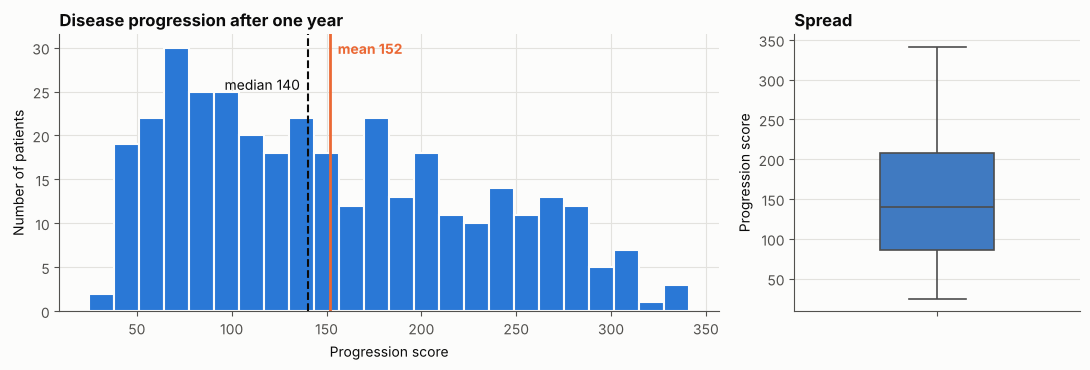

In [11]:
y = train[TARGET]
R["skew_target"], R["kurt_target"] = stats.skew(y), stats.kurtosis(y)
R["target_q1"], R["target_median"], R["target_q3"] = y.quantile([0.25, 0.5, 0.75])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1.3]})
axes[0].hist(y, bins=24, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
axes[0].axvline(y.mean(), color=ORANGE, lw=2); axes[0].axvline(y.median(), color=INK, lw=1.5, ls="--")
axes[0].text(y.mean() + 4, axes[0].get_ylim()[1] * 0.93, f"mean {y.mean():.0f}", color=ORANGE, fontweight="bold")
axes[0].text(y.median() - 4, axes[0].get_ylim()[1] * 0.80, f"median {y.median():.0f}", color=INK, ha="right")
axes[0].set(title="Disease progression after one year", xlabel="Progression score", ylabel="Number of patients")
sns.boxplot(y=y, ax=axes[1], color=BLUE, width=0.4, fliersize=3, linewidth=1.2)
axes[1].set(title="Spread", ylabel="Progression score")
plt.tight_layout()
pc.save_figure(fig, "fig01_target_distribution.png")
print(f"skewness = {R['skew_target']:.2f}, excess kurtosis = {R['kurt_target']:.2f}; Q1/median/Q3 = {R['target_q1']:.0f}/{R['target_median']:.0f}/{R['target_q3']:.0f}")

**What the chart shows.** The histogram counts patients by progression score; the dashed line is the median and the orange line the mean. The box plot summarises the spread.

**Observation.** The scores are spread widely and fairly evenly between roughly 25 and 346. The skewness is only 0.43 and the excess kurtosis -0.88 (flatter than a bell curve); the quartiles are 86 / 140 / 208. There are no extreme outliers.

**Meaning.** A numeric (regression) approach is suitable and the target needs no transformation. Because patients differ so much, even an approximate prediction can help to rank them. The score has no stated unit, so absolute values should not be read as clinical categories.

### 10.2 Distribution of each predictor

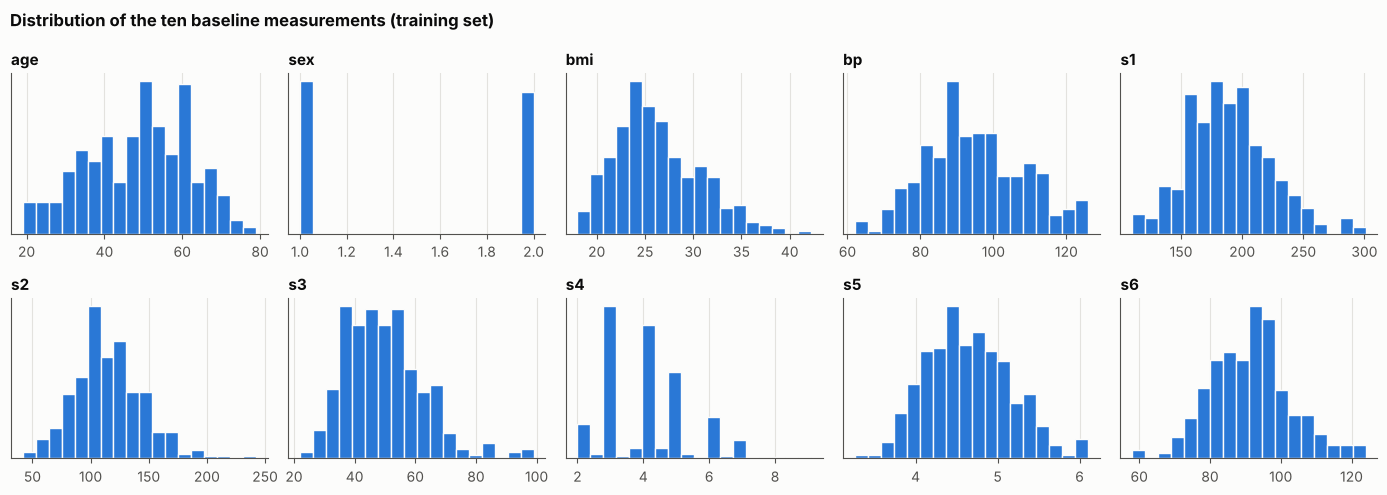

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
skewness,-0.19,0.07,0.63,0.21,0.45,0.51,0.87,0.7,0.29,0.24


In [12]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for ax, col in zip(axes.ravel(), pc.BASE_FEATURES):
    ax.hist(train[col], bins=18, color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.set_title(col, fontsize=11); ax.set_yticks([])
fig.suptitle("Distribution of the ten baseline measurements (training set)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
pc.save_figure(fig, "fig02_feature_distributions.png")
skew = train[pc.BASE_FEATURES].apply(stats.skew).round(2)
R["skew_by_feature"] = skew.to_dict()
skew.to_frame("skewness").T

**What the chart shows.** One histogram per predictor. **Observation.** All skewness values are below 1 in size; the most skewed are `s3` (0.87), `s4` (0.70) and `bmi` (0.63), each with a modest right tail. `sex` is two-valued. **Meaning.** The distributions are reasonable for both linear and tree models, so no log or power transformations are applied (the data are not forced into a shape they do not have).

### 10.3 Relationship of each predictor with progression

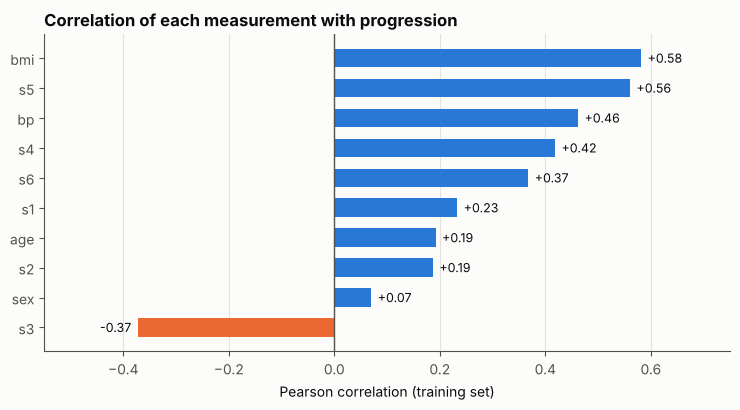

,pearson_r,pearson_p,spearman_rho,spearman_p,significant_after_bonferroni
feature,,,,,
age,0.1923,0.0003,0.1954,0.0002,True
sex,0.0703,0.1875,0.0601,0.2597,False
bmi,0.5818,0.0000,0.5619,0.0000,True
bp,0.4623,0.0000,0.4324,0.0000,True
s1,0.2333,0.0000,0.2567,0.0000,True
s2,0.1871,0.0004,0.2160,0.0000,True
s3,-0.3727,0.0000,-0.3925,0.0000,True
s4,0.4186,0.0000,0.4499,0.0000,True
s5,0.5608,0.0000,0.5844,0.0000,True


In [13]:
rows = []
for col in pc.BASE_FEATURES:
    r, p_r = stats.pearsonr(train[col], train[TARGET])
    rho, p_rho = stats.spearmanr(train[col], train[TARGET])
    rows.append({"feature": col, "pearson_r": r, "pearson_p": p_r, "spearman_rho": rho, "spearman_p": p_rho})
corr_target = pd.DataFrame(rows).set_index("feature")
alpha_bonf = 0.05 / len(pc.BASE_FEATURES)          # Bonferroni: 10 tests
corr_target["significant_after_bonferroni"] = corr_target["spearman_p"] < alpha_bonf
R["alpha_bonferroni"] = alpha_bonf
R["corr_pearson"] = corr_target["pearson_r"].to_dict()
R["corr_spearman"] = corr_target["spearman_rho"].to_dict()
R["corr_sig"] = corr_target["significant_after_bonferroni"].to_dict()
order = corr_target["pearson_r"].sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(order.index, order.values, color=[BLUE if v > 0 else ORANGE for v in order.values], height=0.62)
for i, v in enumerate(order.values):
    ax.text(v + (0.012 if v > 0 else -0.012), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", color=INK, fontsize=9)
ax.axvline(0, color=MUTED, lw=1); ax.set_xlim(-0.55, 0.75)
ax.set(title="Correlation of each measurement with progression", xlabel="Pearson correlation (training set)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig03_correlation_with_target.png")
corr_target.round(4)

In [14]:
# sex is binary, so a rank-based two-group test is used instead of a correlation
a = train.loc[train["sex_2"] == 0, TARGET]; b = train.loc[train["sex_2"] == 1, TARGET]
u, p_sex = stats.mannwhitneyu(a, b, alternative="two-sided")
pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
R["sex_mean_code1"], R["sex_mean_code2"] = a.mean(), b.mean()
R["sex_p"], R["sex_d"] = p_sex, (b.mean() - a.mean()) / pooled
print(f"Mean progression: sex code 1 = {a.mean():.1f} (n={len(a)}), sex code 2 = {b.mean():.1f} (n={len(b)})")
print(f"Mann-Whitney U p-value = {p_sex:.3f}; Cohen's d = {R['sex_d']:.2f}")

Mean progression: sex code 1 = 146.7 (n=183), sex code 2 = 157.5 (n=170)
Mann-Whitney U p-value = 0.259; Cohen's d = 0.14

**What the chart shows.** Each bar is the Pearson correlation between one measurement and progression (positive = higher values go with faster progression).

**Observation.** The strongest relationships are `bmi` (+0.58), `s5` (+0.56) and `bp` (+0.46), followed by `s4` (+0.42), `s3` (-0.37, **negative**: higher HDL goes with slower progression) and `s6` (+0.37). `s1`, `age` and `s2` are weak but present (+0.23, +0.19, +0.19). With ten tests, the Bonferroni threshold is p < 0.005; using Spearman rank correlation, nine of the ten predictors pass it. **`sex` does not:** mean progression is 146.7 for code 1 and 157.5 for code 2 (Mann-Whitney p = 0.26, Cohen's d = 0.14, a small and non-significant difference).

**Meaning and limitation.** These are *associations*. A correlation does not show that BMI or triglycerides *cause* faster progression; other unmeasured factors (diet, medication, duration of illness) may drive both.

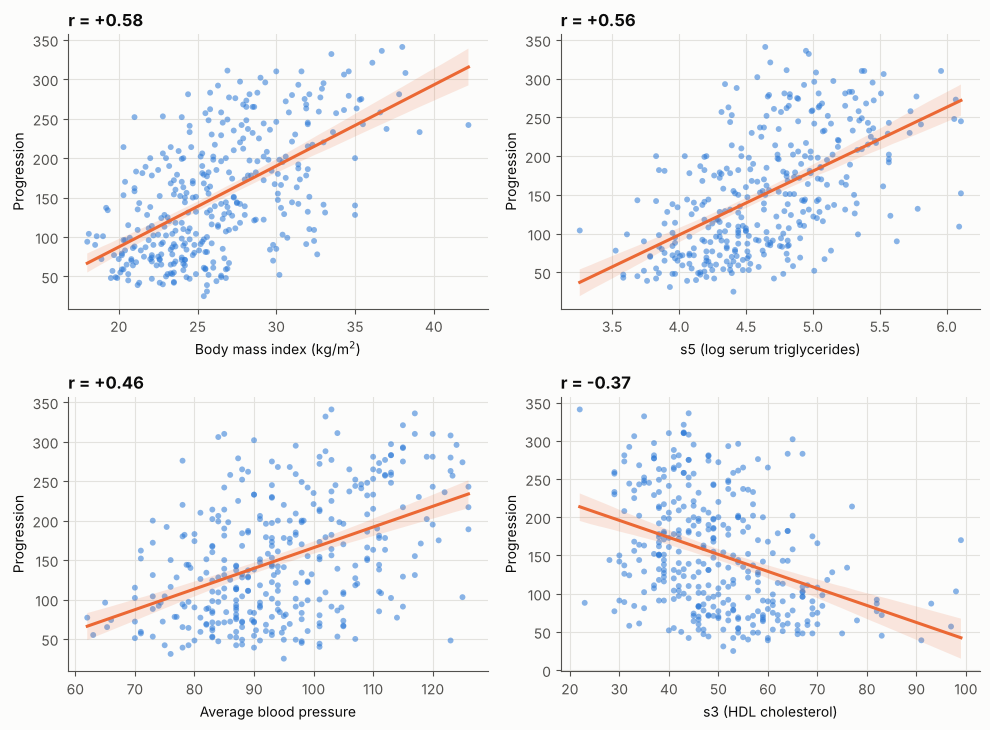

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.4))
for ax, col, label in zip(axes.ravel(), ["bmi", "s5", "bp", "s3"],
                          ["Body mass index (kg/m$^2$)", "s5 (log serum triglycerides)", "Average blood pressure", "s3 (HDL cholesterol)"]):
    sns.regplot(data=train, x=col, y=TARGET, ax=ax, scatter_kws={"s": 18, "alpha": 0.55, "color": BLUE, "edgecolor": "none"},
                line_kws={"color": ORANGE, "lw": 2.2}, ci=95)
    ax.set(xlabel=label, ylabel="Progression", title=f"r = {R['corr_pearson'][col]:+.2f}")
plt.tight_layout()
pc.save_figure(fig, "fig04_scatter_key_features.png")
R["bmi_r2"], R["s5_r2"] = R["corr_pearson"]["bmi"] ** 2, R["corr_pearson"]["s5"] ** 2

**What the chart shows.** Progression plotted against the four most informative predictors, each with a fitted straight line and 95 % confidence band.

**Observation.** The relationships are positive for BMI, `s5` and blood pressure and negative for HDL (`s3`). The cloud around each line is wide: BMI alone accounts for about 34% of the variation and `s5` for about 31%. There is no strong curvature.

**Meaning.** Each measurement carries real but incomplete information, and the roughly straight relationships suggest that a linear model may do well. Large individual scatter warns that predictions will be approximate.

### 10.4 Relationships among the predictors (multicollinearity)

Predictor pairs with |r| >= 0.7:
s2  s1    0.89
s4  s3   -0.75

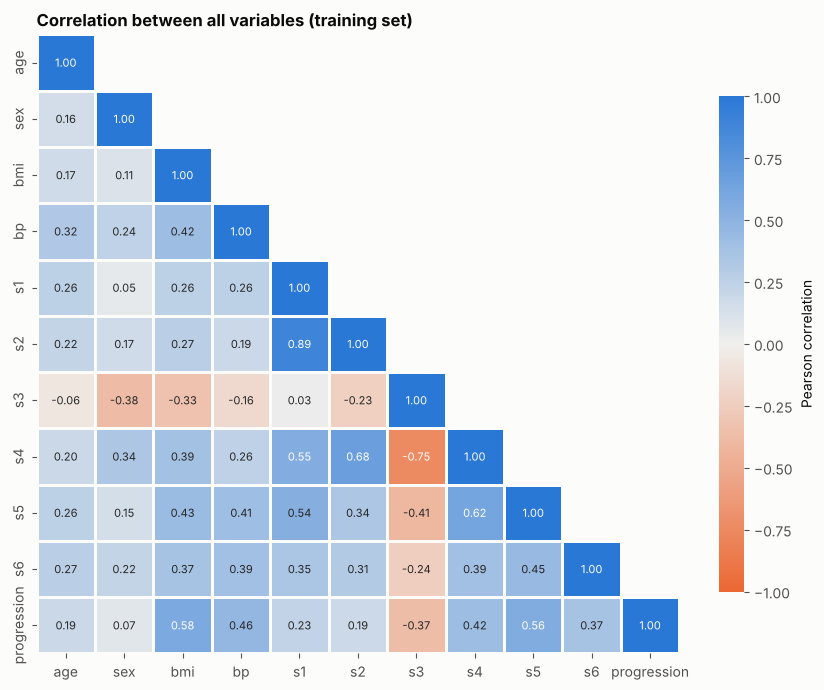

In [16]:
corr_matrix = train[pc.BASE_FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.6, 7))
sns.heatmap(corr_matrix, mask=mask, cmap=DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor=SURFACE, cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation between all variables (training set)"); ax.grid(False)
plt.tight_layout()
pc.save_figure(fig, "fig05_correlation_heatmap.png")
pairs = (corr_matrix.loc[pc.BASE_FEATURES, pc.BASE_FEATURES].where(~np.triu(np.ones((10, 10), dtype=bool))).stack())
strong = pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False)
R["strong_pairs"] = {f"{a}-{b}": v for (a, b), v in strong.items()}
print("Predictor pairs with |r| >= 0.7:"); print(strong.round(2).to_string())

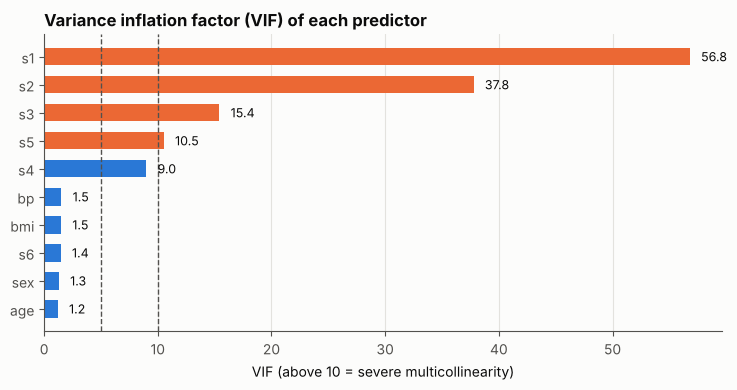

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
VIF,1.2,1.3,1.5,1.5,56.8,37.8,15.4,9.0,10.5,1.4


In [17]:
vif = pc.vif_table(train, pc.BASE_FEATURES)
R["vif"] = vif.to_dict()
fig, ax = plt.subplots(figsize=(7.5, 4))
vs = vif.sort_values()
ax.barh(vs.index, vs.values, color=[ORANGE if v > 10 else BLUE for v in vs.values], height=0.62)
for i, v in enumerate(vs.values):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)
ax.axvline(5, color=MUTED, ls="--", lw=1); ax.axvline(10, color=MUTED, ls="--", lw=1)
ax.set(title="Variance inflation factor (VIF) of each predictor", xlabel="VIF (above 10 = severe multicollinearity)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig06_vif.png")
vif.round(1).to_frame("VIF").T

**What the charts show.** The heat map shows how strongly every pair of variables moves together; the bar chart shows the *variance inflation factor* (VIF): how much of each predictor can be reproduced from the others (above 10 is considered severe).

**Observation.** Two predictor pairs are strongly related: `s1`-`s2` (r = +0.89, total and LDL cholesterol) and `s3`-`s4` (r = -0.75, HDL and the cholesterol/HDL ratio). The VIFs are very high for `s1` (56.8), `s2` (37.8), `s3` (15.4) and `s5` (10.5), and borderline for `s4` (9.0); the other predictors are below 2.

**Meaning.** The lipid measurements overlap. Predictions are hardly affected, but the **individual coefficients of `s1`-`s4` become unstable and cannot be interpreted one by one**. This is why regularised models (Ridge, Lasso) are tried and why importance is interpreted for groups of variables.

## 11. Feature engineering

Feature engineering adds columns that express domain knowledge. Each was added for a stated reason and is **tested**, not assumed to help:

| New feature | Definition | Reason |
|---|---|---|
| `sex_2` | 1 if sex code is 2, else 0 | turns a code into a proper binary variable |
| `bmi_category` | BMI under 25 / 25 to 29.9 / 30 and over | standard adult BMI cut-offs (WHO); clinicians think in these classes. The "underweight" class (under 18.5) has only 2 patients, so it is merged with the first class |
| `age_group` | 19-39 / 40-49 / 50-59 / 60+ | lets the model use a stepwise age effect |
| `ldl_hdl_ratio` | `s2 / s3` | a common lipid-balance measure that combines two related predictors |

Mean progression by BMI class:
              count   mean  median  diff_vs_overall
bmi_category                                       
Under 25        154  110.9    96.0            -41.0
25 to 29.9      123  165.1   168.0             13.1
30 and over      76  213.8   225.5             61.9
Kruskal-Wallis p = 9.57e-21

Mean progression by age group:
           count   mean  median  diff_vs_overall
age_group                                       
19-39         95  133.6   126.0            -18.3
40-49         77  138.9   123.0            -13.0
50-59         97  163.9   154.0             12.0
60+           84  170.7   169.0             18.8
Kruskal-Wallis p = 1.66e-03

corr(ldl_hdl_ratio, progression) = +0.332   vs   corr(s2) = +0.187, corr(s3) = -0.373

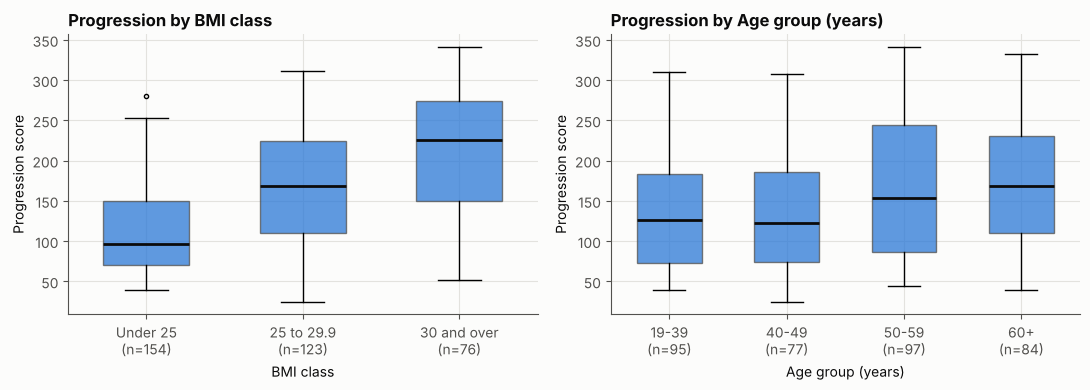

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["bmi_category", "age_group"], ["BMI class", "Age group (years)"]):
    cats = list(train[col].cat.categories)
    data = [train.loc[train[col] == c, TARGET] for c in cats]
    bp = ax.boxplot(data, tick_labels=[f"{c}\n(n={len(d)})" for c, d in zip(cats, data)], patch_artist=True, widths=0.55,
                    medianprops={"color": INK, "lw": 2}, flierprops={"markersize": 3})
    for patch in bp["boxes"]:
        patch.set(facecolor=BLUE, alpha=0.75, edgecolor=MUTED)
    ax.set(title=f"Progression by {title}", ylabel="Progression score", xlabel=title)
plt.tight_layout()
pc.save_figure(fig, "fig07_progression_by_engineered_groups.png")

seg_bmi = pc.segment_summary(train, "bmi_category"); seg_age = pc.segment_summary(train, "age_group")
H_bmi, p_bmi = stats.kruskal(*[g[TARGET] for _, g in train.groupby("bmi_category", observed=True)])
H_age, p_age = stats.kruskal(*[g[TARGET] for _, g in train.groupby("age_group", observed=True)])
R["bmi_groups"] = seg_bmi[["count", "mean"]].round(1).to_dict("index"); R["bmi_kw_p"] = p_bmi
R["age_groups"] = seg_age[["count", "mean"]].round(1).to_dict("index"); R["age_kw_p"] = p_age
R["ratio_corr"] = train["ldl_hdl_ratio"].corr(train[TARGET])
print("Mean progression by BMI class:"); print(seg_bmi.round(1).to_string()); print(f"Kruskal-Wallis p = {p_bmi:.2e}\n")
print("Mean progression by age group:"); print(seg_age.round(1).to_string()); print(f"Kruskal-Wallis p = {p_age:.2e}\n")
print(f"corr(ldl_hdl_ratio, progression) = {R['ratio_corr']:+.3f}   vs   corr(s2) = {R['corr_pearson']['s2']:+.3f}, corr(s3) = {R['corr_pearson']['s3']:+.3f}")

### 11.1 Do the engineered features actually help?

In [19]:
BASE_NUM = ["age", "sex_2", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
EXT_NUM, EXT_CAT = BASE_NUM + ["ldl_hdl_ratio"], ["bmi_category", "age_group"]
X_train_all, y_train = train, train[TARGET]
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)     # used for every comparison below
from sklearn.model_selection import cross_val_score


def cv_rmse(model, num, cat=()):
    scores = -cross_val_score(pc.make_pipeline(model, num, cat), X_train_all, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error")
    return scores.mean(), scores.std(ddof=1) / np.sqrt(len(scores))


tests = {"Ridge (alpha=10)": lambda: Ridge(alpha=10.0),
         "Gradient Boosting (small)": lambda: GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2,
                                                                      subsample=0.8, random_state=RANDOM_STATE)}
fe_rows = []
for name, make in tests.items():
    b, b_se = cv_rmse(make(), BASE_NUM)
    e, e_se = cv_rmse(make(), EXT_NUM, EXT_CAT)
    fe_rows.append({"model": name, "base features RMSE": b, "with engineered RMSE": e, "change": e - b, "SE (base)": b_se})
fe_check = pd.DataFrame(fe_rows).set_index("model")
R["fe_check"] = fe_check.round(3).to_dict("index")
fe_check.round(3)

,base features RMSE,with engineered RMSE,change,SE (base)
model,,,,
Ridge (alpha=10),55.028,55.377,0.349,1.943
Gradient Boosting (small),57.292,57.638,0.345,1.963


In [20]:
# Decision rule (fixed in advance): keep the engineered features only if they lower the
# cross-validated RMSE of BOTH test models by more than one standard error.
USE_ENGINEERED = bool(((-fe_check["change"]) > fe_check["SE (base)"]).all())
R["use_engineered"] = USE_ENGINEERED
NUM_COLS, CAT_COLS = (EXT_NUM, EXT_CAT) if USE_ENGINEERED else (BASE_NUM, [])
print("Engineered features adopted for modelling:", USE_ENGINEERED)
print("Numeric inputs:", NUM_COLS); print("Categorical inputs:", CAT_COLS)

Engineered features adopted for modelling: False
Numeric inputs: ['age', 'sex_2', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Categorical inputs: []

**Observation (descriptive).** Progression rises steeply across BMI classes: 110.9 (under 25, n = 154), 165.1 (25 to 29.9, n = 123) and 213.8 (30 and over, n = 76); Kruskal-Wallis p = 9.6e-21. Age shows a milder step: 133.6, 138.9, 163.9 and 170.7 for the four groups (p = 0.0017). The LDL/HDL ratio correlates +0.33 with progression, no stronger than HDL alone (-0.37).

**Do they improve prediction? No.** Under the pre-set rule (adopt only if cross-validated RMSE falls by more than one standard error for *both* test models), the engineered features **did not help**: RMSE changed by +0.35 for Ridge and +0.34 for Gradient Boosting (a positive change means slightly worse), against a standard error of about 1.9. The models already contain the underlying numbers, so the groups add no new information. The final models therefore use the ten original predictors (with `sex` as `sex_2`). The groups remain useful for *explaining* results to non-technical readers (sections 14-15).

## 12. Model development

**Algorithms and why they were chosen.**

* **Baseline - predict the training average.** The minimum standard any model must beat.
* **Linear Regression.** Simple, transparent, a strong benchmark when relationships are roughly straight (as in section 10.3).
* **Ridge and Lasso.** Linear models with a penalty that stabilises coefficients when predictors overlap (section 10.4). Lasso can also switch weak predictors off.
* **Decision Tree.** Easy-to-read if-then rules; captures non-linear steps but is unstable.
* **Random Forest** and **Gradient Boosting.** Ensembles of many trees that can capture non-linear effects and interactions. (XGBoost was not available in the build environment; scikit-learn's Gradient Boosting is the same family.)

**Method.** Every model is a pipeline (impute, scale, model). Settings are tuned by grid search with **5-fold cross-validation repeated twice** on the training set only, scored by RMSE. The test set is not used for tuning or for choosing the model.

In [21]:
X_train, y_train = train[NUM_COLS + CAT_COLS], train[TARGET]
X_test, y_test = test[NUM_COLS + CAT_COLS], test[TARGET]
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}


def make(model):
    return pc.make_pipeline(model, NUM_COLS, CAT_COLS)


candidates = {
    "Ridge": (make(Ridge()), {"model__alpha": np.logspace(-2, 3, 26)}),
    "Lasso": (make(Lasso(max_iter=50000)), {"model__alpha": np.logspace(-3, 1, 25)}),
    "Linear Regression": (make(LinearRegression()), {}),
    "Decision Tree": (make(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                      {"model__max_depth": [2, 3, 4, 5], "model__min_samples_leaf": [5, 10, 20, 30]}),
    "Random Forest": (make(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                      {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [3, 6, 12],
                       "model__max_features": [0.33, 0.6, 1.0]}),
    "Gradient Boosting": (make(GradientBoostingRegressor(random_state=RANDOM_STATE)),
                          {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.01, 0.03, 0.06],
                           "model__max_depth": [2, 3], "model__subsample": [0.7, 1.0]}),
}
searches = {}
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    n_combo = len(gs.cv_results_["params"])
    print(f"{name:<18} tuned over {n_combo:>3} settings | best CV RMSE = {-gs.best_score_:.2f} | best settings: "
          + (", ".join(f"{k.split('__')[1]}={v:.4g}" if isinstance(v, float) else f"{k.split('__')[1]}={v}" for k, v in gs.best_params_.items()) or "none"))

Ridge              tuned over  26 settings | best CV RMSE = 55.01 | best settings: alpha=25.12
Lasso              tuned over  25 settings | best CV RMSE = 55.04 | best settings: alpha=1
Linear Regression  tuned over   1 settings | best CV RMSE = 55.18 | best settings: none
Decision Tree      tuned over  16 settings | best CV RMSE = 61.67 | best settings: max_depth=4, min_samples_leaf=30
Random Forest      tuned over  27 settings | best CV RMSE = 56.14 | best settings: max_depth=5, max_features=0.6, min_samples_leaf=6
Gradient Boosting  tuned over  36 settings | best CV RMSE = 56.24 | best settings: learning_rate=0.01, max_depth=2, n_estimators=400, subsample=0.7

In [22]:
# Baseline: always predict the training mean (no learning). Same cross-validation.
from sklearn.model_selection import cross_validate
base_pipe = make(DummyRegressor(strategy="mean"))
base_cv = cross_validate(base_pipe, X_train, y_train, cv=cv, scoring=SCORING)
baseline = base_pipe.fit(X_train, y_train)
R["baseline_cv_rmse"] = -base_cv["test_rmse"].mean()
R["baseline_cv_mae"] = -base_cv["test_mae"].mean()
R["baseline_test"] = pc.regression_metrics(y_test, baseline.predict(X_test))
print(f"Baseline (predict the training mean): CV RMSE = {R['baseline_cv_rmse']:.2f}, CV MAE = {R['baseline_cv_mae']:.2f}")
print("Baseline test metrics:", {k: round(v, 3) for k, v in R["baseline_test"].items()})

Baseline (predict the training mean): CV RMSE = 76.89, CV MAE = 65.64
Baseline test metrics: {'MAE': 66.641, 'MSE': 6029.712, 'RMSE': 77.651, 'R2': -0.0}

## 13. Model evaluation

**Metrics used (regression).**

* **MAE** - the average size of the error, in progression points. Easy to explain; treats all errors equally.
* **MSE / RMSE** - squared errors punish large mistakes more; RMSE returns to the original points scale. RMSE is the main metric because large misses on high-risk patients matter most.
* **R-squared** - the share of the variation in progression explained by the model (0 = no better than the average, 1 = perfect).

Accuracy, precision, recall, F1 and ROC-AUC apply to classification; they are used in the extension in section 15.3, where the question becomes "is this patient a fast progressor?".

**Model selection rule (fixed in advance).** Use cross-validation results only. Among the tuned models whose cross-validated RMSE is within **one standard error** of the best, choose the **simplest and most interpretable** (the "one-standard-error rule"). A slightly more accurate but harder-to-explain model is not worth it when the difference is within noise.

In [23]:
rows, K = [], cv.get_n_splits()
for name, gs in searches.items():
    i = gs.best_index_
    res = gs.cv_results_
    tr = pc.regression_metrics(y_train, gs.predict(X_train))
    te = pc.regression_metrics(y_test, gs.predict(X_test))
    rows.append({"model": name,
                 "cv_rmse": -res["mean_test_rmse"][i], "cv_rmse_se": res["std_test_rmse"][i] / np.sqrt(K),
                 "cv_mae": -res["mean_test_mae"][i], "cv_r2": res["mean_test_r2"][i],
                 "train_rmse": tr["RMSE"], "train_r2": tr["R2"],
                 "test_mae": te["MAE"], "test_mse": te["MSE"], "test_rmse": te["RMSE"], "test_r2": te["R2"]})
results = pd.DataFrame(rows).set_index("model")
# Add the baseline row for comparison
results.loc["Baseline (mean)"] = {"cv_rmse": R["baseline_cv_rmse"], "cv_rmse_se": base_cv["test_rmse"].std(ddof=1) / np.sqrt(K),
                                  "cv_mae": R["baseline_cv_mae"], "cv_r2": base_cv["test_r2"].mean(),
                                  "train_rmse": pc.regression_metrics(y_train, baseline.predict(X_train))["RMSE"],
                                  "train_r2": pc.regression_metrics(y_train, baseline.predict(X_train))["R2"],
                                  "test_mae": R["baseline_test"]["MAE"], "test_mse": R["baseline_test"]["MSE"],
                                  "test_rmse": R["baseline_test"]["RMSE"], "test_r2": R["baseline_test"]["R2"]}
results = results.sort_values("cv_rmse")
R["results_table"] = results.round(3).to_dict("index")
results.round(3)

,cv_rmse,cv_rmse_se,cv_mae,cv_r2,train_rmse,train_r2,test_mae,test_mse,test_rmse,test_r2
model,,,,,,,,,,
Ridge,55.009,1.807,45.126,0.478,54.113,0.504,42.270,2751.146,52.451,0.544
Lasso,55.040,1.827,45.162,0.477,54.147,0.503,42.557,2762.027,52.555,0.542
Linear Regression,55.178,1.807,45.211,0.474,53.929,0.507,41.689,2701.649,51.977,0.552
Random Forest,56.144,1.750,46.627,0.456,44.434,0.666,43.557,3003.356,54.803,0.502
Gradient Boosting,56.241,1.755,46.743,0.454,46.818,0.629,43.945,3048.112,55.210,0.494
Decision Tree,61.673,1.931,49.509,0.342,54.059,0.505,46.994,3676.406,60.633,0.390
Baseline (mean),76.887,1.210,65.638,-0.009,76.842,0.000,66.641,6029.712,77.651,-0.000


**What happened.** Linear models reached a cross-validated RMSE of about 55.0, the two ensembles about 56.1 and 56.2, and the single decision tree 61.7. The baseline scored 76.9.

**Interpretation.** Five of the six models are within about one standard error (1.8) of each other, so **flexible models gave no real advantage over linear ones**. This fits the nearly straight relationships seen in EDA. The single tree is clearly worse because one tree is unstable and, with only 353 training patients, each leaf holds few patients.

In [24]:
# Model selection uses ONLY the cross-validated results on the training data.
# One-standard-error rule: among the tuned models whose CV RMSE is within one
# standard error of the best, choose the simplest / most interpretable one.
INTERPRETABILITY = ["Linear Regression", "Ridge", "Lasso", "Decision Tree", "Gradient Boosting", "Random Forest"]
tuned = results.drop(index="Baseline (mean)")
best_name = tuned["cv_rmse"].idxmin()
limit = tuned.loc[best_name, "cv_rmse"] + tuned.loc[best_name, "cv_rmse_se"]
eligible = [m for m in INTERPRETABILITY if m in tuned.index and tuned.loc[m, "cv_rmse"] <= limit]
FINAL_NAME = eligible[0]
final_model = searches[FINAL_NAME].best_estimator_
R["lowest_cv_model"], R["cv_limit"] = best_name, limit
R["eligible_models"], R["final_name"] = eligible, FINAL_NAME
R["final_params"] = {k.split("__")[1]: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)
                     for k, v in searches[FINAL_NAME].best_params_.items()}
print(f"Lowest CV RMSE: {best_name} ({tuned.loc[best_name, 'cv_rmse']:.2f}); one-SE limit = {limit:.2f}")
print("Models within the limit:", eligible)
print("Selected final model   :", FINAL_NAME, R["final_params"])

Lowest CV RMSE: Ridge (55.01); one-SE limit = 56.82
Models within the limit: ['Linear Regression', 'Ridge', 'Lasso', 'Gradient Boosting', 'Random Forest']
Selected final model   : Linear Regression {}

In [25]:
pred_test = final_model.predict(X_test)
pred_train = final_model.predict(X_train)
m_test = pc.regression_metrics(y_test, pred_test)
m_train = pc.regression_metrics(y_train, pred_train)
ci = pc.bootstrap_metric_ci(y_test, pred_test, n_boot=2000)
R["test"], R["train"], R["test_ci"] = m_test, m_train, ci
R["cv"] = {"RMSE": results.loc[FINAL_NAME, "cv_rmse"], "MAE": results.loc[FINAL_NAME, "cv_mae"], "R2": results.loc[FINAL_NAME, "cv_r2"]}
R["rmse_gain_vs_baseline_pct"] = 100 * (1 - m_test["RMSE"] / R["baseline_test"]["RMSE"])
R["mae_gain_vs_baseline_pct"] = 100 * (1 - m_test["MAE"] / R["baseline_test"]["MAE"])
print(f"{FINAL_NAME} -> TEST: MAE {m_test['MAE']:.2f} | MSE {m_test['MSE']:.1f} | RMSE {m_test['RMSE']:.2f} | R2 {m_test['R2']:.3f}")
print(f"          -> TRAIN: RMSE {m_train['RMSE']:.2f} | R2 {m_train['R2']:.3f}   CV: RMSE {R['cv']['RMSE']:.2f} | R2 {R['cv']['R2']:.3f}")
print("Bootstrap 95% intervals on the test set:", {k: tuple(round(x, 3) for x in v) for k, v in ci.items()})
print(f"Improvement over the baseline on the test set: RMSE {R['rmse_gain_vs_baseline_pct']:.1f}%, MAE {R['mae_gain_vs_baseline_pct']:.1f}%")

Linear Regression -> TEST: MAE 41.69 | MSE 2701.6 | RMSE 51.98 | R2 0.552
          -> TRAIN: RMSE 53.93 | R2 0.507   CV: RMSE 55.18 | R2 0.474
Bootstrap 95% intervals on the test set: {'RMSE': (45.037, 58.636), 'MAE': (35.539, 48.334), 'R2': (0.388, 0.667)}
Improvement over the baseline on the test set: RMSE 33.1%, MAE 37.4%

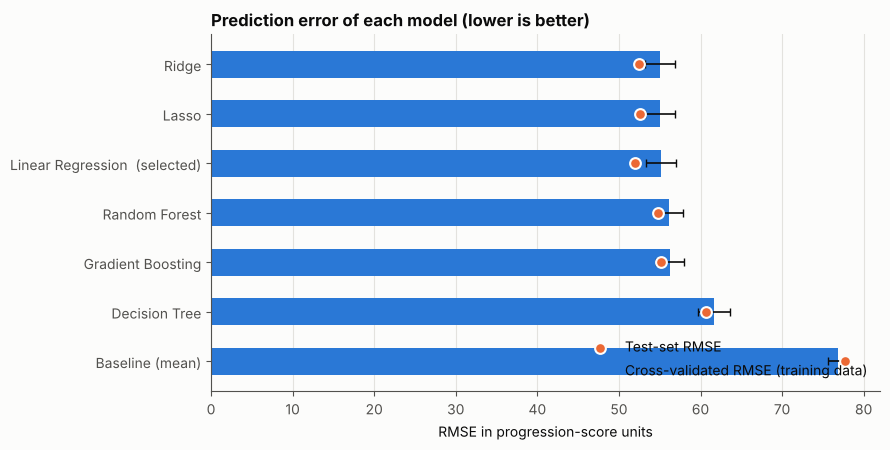

PosixPath('/home/claude/Final_Data_Science_Capstone/visualizations/generated_charts/fig08_model_comparison.png')

In [26]:
order = results.sort_values("cv_rmse", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.6))
y_pos = np.arange(len(order))
ax.barh(y_pos, order["cv_rmse"], xerr=order["cv_rmse_se"], color=BLUE, height=0.55, label="Cross-validated RMSE (training data)",
        error_kw={"ecolor": INK, "lw": 1.2, "capsize": 3})
ax.scatter(order["test_rmse"], y_pos, color=ORANGE, s=60, zorder=3, label="Test-set RMSE", edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y_pos, [f"{n}  (selected)" if n == FINAL_NAME else n for n in order.index])
ax.set(title="Prediction error of each model (lower is better)", xlabel="RMSE in progression-score units")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig08_model_comparison.png")

**Selection.** The lowest cross-validated RMSE belongs to **Ridge** (55.01); the one-standard-error limit is 56.82. Five models fall inside it, and the simplest is **Linear Regression**, which is the selected final model. Its tuned settings: none (it has no hyper-parameters).

**Final performance on the unseen test patients** (89 patients, used once):

| Metric | Result | 95 % bootstrap interval |
|---|---|---|
| MAE | 41.7 points | 35.5 to 48.3 |
| MSE | 2702 | - |
| RMSE | 52.0 points | 45.0 to 58.6 |
| R-squared | 0.55 | 0.39 to 0.67 |

**Interpretation.** The model's typical error is about 42 points (MAE) when patients differ by a standard deviation of about 78. Compared with the baseline it cuts RMSE by **33 %** (test) and MAE by 37 %; the cross-validated gain is also above the 25 % success criterion. R-squared of 0.55 means the ten baseline measurements explain a little over half of the variation in progression; the cross-validated R-squared is lower (0.47), so **a realistic expectation for new patients is an R-squared of roughly 0.45 to 0.55**. The test result is slightly better than the cross-validation result because the test set is small (89 patients; see the wide intervals) and should not be over-read.

**Strengths:** transparent, stable, no overfitting, clearly better than the baseline. **Weaknesses:** about half of the variation stays unexplained and individual predictions can be far off (section 14).

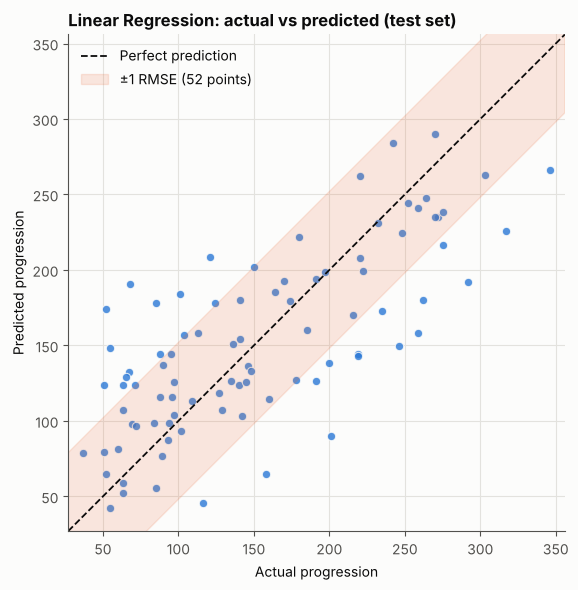

PosixPath('/home/claude/Final_Data_Science_Capstone/visualizations/generated_charts/fig09_actual_vs_predicted.png')

In [27]:
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(y_test, pred_test, color=BLUE, s=36, alpha=0.8, edgecolor=SURFACE, linewidth=0.8)
lims = [min(y_test.min(), pred_test.min()) - 10, max(y_test.max(), pred_test.max()) + 10]
ax.plot(lims, lims, color=INK, lw=1.3, ls="--", label="Perfect prediction")
ax.fill_between(lims, np.array(lims) - m_test["RMSE"], np.array(lims) + m_test["RMSE"], color=ORANGE, alpha=0.15,
                label=f"\u00b11 RMSE ({m_test['RMSE']:.0f} points)")
ax.set(xlim=lims, ylim=lims, xlabel="Actual progression", ylabel="Predicted progression",
       title=f"{FINAL_NAME}: actual vs predicted (test set)")
ax.legend(loc="upper left"); ax.set_aspect("equal")
plt.tight_layout()
pc.save_figure(fig, "fig09_actual_vs_predicted.png")

### 13.1 Overfitting and underfitting checks

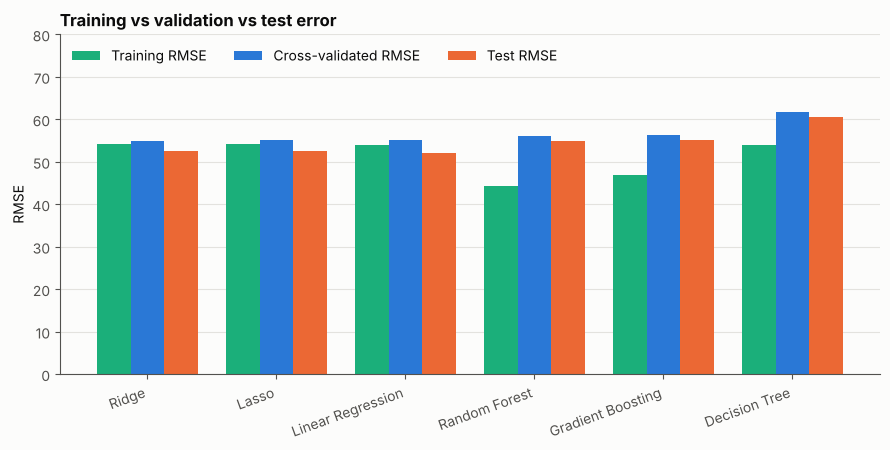

model,Ridge,Lasso,Linear Regression,Random Forest,Gradient Boosting,Decision Tree
CV RMSE minus train RMSE,0.9,0.89,1.25,11.71,9.42,7.61


In [28]:
fig, ax = plt.subplots(figsize=(9, 4.6))
names = [n for n in results.index if n != "Baseline (mean)"]
x = np.arange(len(names)); w = 0.26
ax.bar(x - w, results.loc[names, "train_rmse"], w, color=AQUA, label="Training RMSE")
ax.bar(x, results.loc[names, "cv_rmse"], w, color=BLUE, label="Cross-validated RMSE")
ax.bar(x + w, results.loc[names, "test_rmse"], w, color=ORANGE, label="Test RMSE")
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set(title="Training vs validation vs test error", ylabel="RMSE"); ax.legend(ncol=3, loc="upper left"); ax.set_ylim(0, 80)
ax.grid(axis="x", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig10_overfitting_check.png")
gap = (results.loc[names, "cv_rmse"] - results.loc[names, "train_rmse"]).round(2)
R["train_cv_gap"] = gap.to_dict()
gap.to_frame("CV RMSE minus train RMSE").T

Learning curve: validation RMSE 59.7 (n=56) -> 55.0 (n=282); final train/validation gap = 1.1

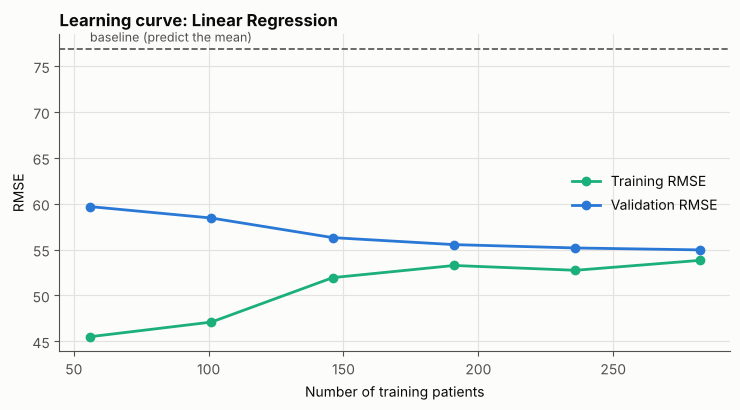

In [29]:
sizes, tr_scores, va_scores = learning_curve(clone(final_model), X_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                             train_sizes=np.linspace(0.2, 1.0, 6), scoring="neg_root_mean_squared_error")
tr_m, va_m = -tr_scores.mean(axis=1), -va_scores.mean(axis=1)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sizes, tr_m, "o-", color=AQUA, lw=2, label="Training RMSE")
ax.plot(sizes, va_m, "o-", color=BLUE, lw=2, label="Validation RMSE")
ax.axhline(R["baseline_cv_rmse"], color=MUTED, ls="--", lw=1.2); ax.text(sizes[0], R["baseline_cv_rmse"] + 0.8, "baseline (predict the mean)", color=MUTED, fontsize=9)
ax.set(title=f"Learning curve: {FINAL_NAME}", xlabel="Number of training patients", ylabel="RMSE"); ax.legend(loc="center right")
plt.tight_layout()
pc.save_figure(fig, "fig11_learning_curve.png")
R["lc_final_gap"], R["lc_val_first"], R["lc_val_last"] = va_m[-1] - tr_m[-1], va_m[0], va_m[-1]
print(f"Learning curve: validation RMSE {va_m[0]:.1f} (n={sizes[0]}) -> {va_m[-1]:.1f} (n={sizes[-1]}); final train/validation gap = {R['lc_final_gap']:.1f}")

**Overfitting check.** For the selected model the training RMSE is 53.9, the cross-validated RMSE 55.2 and the test RMSE 52.0: the three are close (training-to-validation gap 1.2), so the model is **not overfitted**. The tree-based models show the typical warning sign: Random Forest and Gradient Boosting fit the training patients much better than new ones (gaps of 11.7 and 9.4 RMSE points), yet they do not do better on validation data.

**Underfitting check.** A linear model explaining 51% of the variation on its own training data could be underfitting, but the flexible models, which can fit much more, did *not* validate any better. The remaining variation therefore seems to be **missing information** (factors not recorded in these ten measurements) rather than a model that is too simple.

**Learning curve.** As the training set grows from 56 to 353 patients the validation RMSE falls from 59.7 to 55.0 and flattens; the final gap between training and validation error is only 1.1. More patients of the same kind would add little. **Better or additional measurements would help more than more rows.**

## 14. Error analysis

Error analysis asks *where* and *why* the model is wrong. The residual is `actual - predicted`: a positive residual means the model **under-predicted** (the patient progressed faster than expected), which is the more worrying direction for a risk tool.

Mean residual (bias) = 0.10; SD = 52.3; Shapiro-Wilk p = 0.614
Spearman(predicted, |residual|) = +0.16 (p = 0.128)
Share of test patients predicted within +/-25 points: 42%, within +/-50 points: 65%

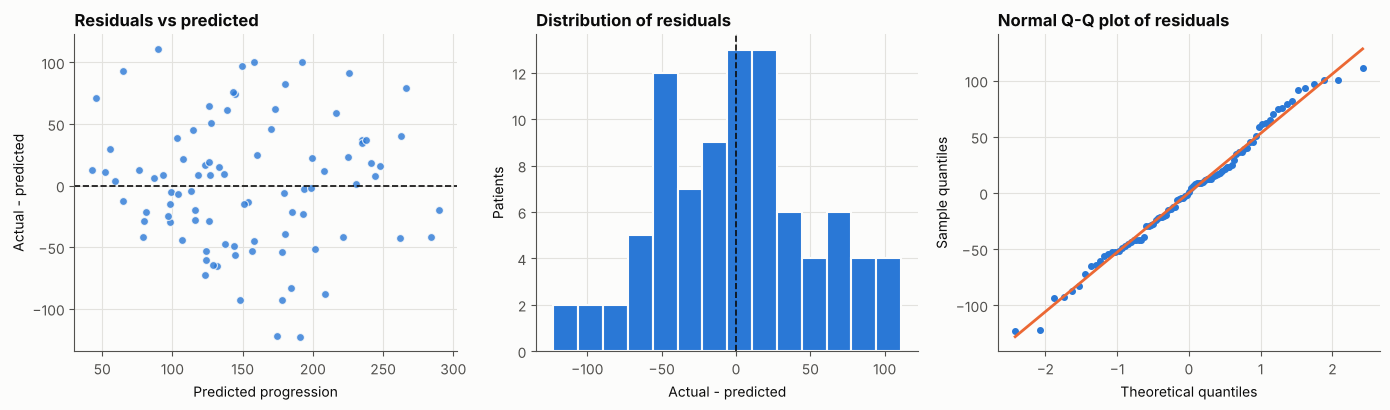

In [30]:
resid = y_test - pred_test                                   # positive = the model under-predicted
R["resid_mean"], R["resid_sd"] = resid.mean(), resid.std()
R["resid_shapiro_p"] = stats.shapiro(resid)[1]
R["resid_vs_pred_rho"], R["resid_vs_pred_p"] = stats.spearmanr(pred_test, resid.abs())
for t in (25, 50):
    R[f"within_{t}"] = float((resid.abs() <= t).mean())
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].scatter(pred_test, resid, color=BLUE, s=32, alpha=0.8, edgecolor=SURFACE, linewidth=0.8)
axes[0].axhline(0, color=INK, lw=1.2, ls="--"); axes[0].set(title="Residuals vs predicted", xlabel="Predicted progression", ylabel="Actual - predicted")
axes[1].hist(resid, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=1.5); axes[1].axvline(0, color=INK, lw=1.2, ls="--")
axes[1].set(title="Distribution of residuals", xlabel="Actual - predicted", ylabel="Patients")
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].get_lines()[0].set(color=BLUE, markersize=4); axes[2].get_lines()[1].set(color=ORANGE, lw=2)
axes[2].set(title="Normal Q-Q plot of residuals", xlabel="Theoretical quantiles", ylabel="Sample quantiles")
plt.tight_layout()
pc.save_figure(fig, "fig12_residual_diagnostics.png")
print(f"Mean residual (bias) = {R['resid_mean']:.2f}; SD = {R['resid_sd']:.1f}; Shapiro-Wilk p = {R['resid_shapiro_p']:.3f}")
print(f"Spearman(predicted, |residual|) = {R['resid_vs_pred_rho']:+.2f} (p = {R['resid_vs_pred_p']:.3f})")
print(f"Share of test patients predicted within +/-25 points: {100*R['within_25']:.0f}%, within +/-50 points: {100*R['within_50']:.0f}%")

By actual progression level:
              n   MAE  mean_residual
actual_band                         
Lowest 25%   21  48.6          -43.2
25-50%       23  32.0          -18.7
50-75%       20  36.7           16.7
Highest 25%  25  48.8           40.5

By BMI class:
               n   MAE  mean_residual
bmi_category                         
Under 25      34  31.5           -1.0
25 to 29.9    32  50.6            8.4
30 and over   23  44.4           -9.8

By sex code:
      n   MAE  mean_residual
sex                         
1.0  52  42.8            7.4
2.0  37  40.1          -10.1

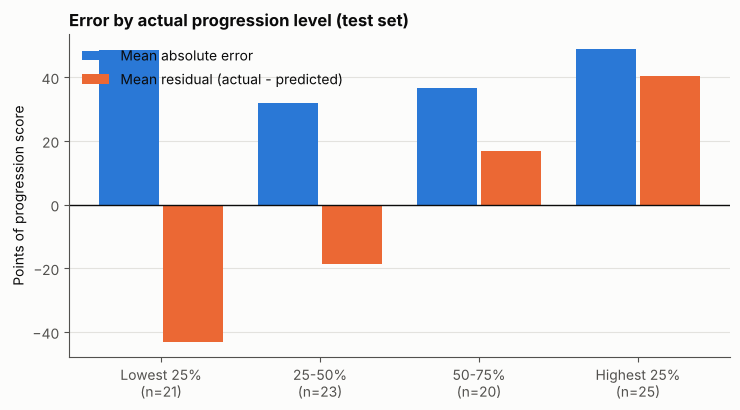

In [31]:
# Where does the model make larger errors? Group the TEST patients by their ACTUAL progression
# (cut-offs from the training quartiles) and by other characteristics.
q = train[TARGET].quantile([0.25, 0.5, 0.75]).values
test_err = test.copy(); test_err["pred"] = pred_test; test_err["resid"] = resid; test_err["abs_err"] = resid.abs()
test_err["actual_band"] = pd.cut(test_err[TARGET], [-np.inf, q[0], q[1], q[2], np.inf],
                                 labels=["Lowest 25%", "25-50%", "50-75%", "Highest 25%"])
by_band = test_err.groupby("actual_band", observed=True).agg(n=("resid", "size"), MAE=("abs_err", "mean"), mean_residual=("resid", "mean"))
by_bmi = test_err.groupby("bmi_category", observed=True).agg(n=("resid", "size"), MAE=("abs_err", "mean"), mean_residual=("resid", "mean"))
by_sex = test_err.groupby("sex", observed=True).agg(n=("resid", "size"), MAE=("abs_err", "mean"), mean_residual=("resid", "mean"))
R["err_by_band"] = by_band.round(2).to_dict("index"); R["err_by_bmi"] = by_bmi.round(2).to_dict("index"); R["err_by_sex"] = {int(k): v for k, v in by_sex.round(2).to_dict("index").items()}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
xb = np.arange(len(by_band))
ax.bar(xb - 0.2, by_band["MAE"], 0.38, color=BLUE, label="Mean absolute error")
ax.bar(xb + 0.2, by_band["mean_residual"], 0.38, color=ORANGE, label="Mean residual (actual - predicted)")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(xb, [f"{b}\n(n={n})" for b, n in zip(by_band.index, by_band["n"])])
ax.set(title="Error by actual progression level (test set)", ylabel="Points of progression score"); ax.legend(loc="lower right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig13_error_by_progression_level.png")
print("By actual progression level:"); print(by_band.round(1).to_string())
print("\nBy BMI class:"); print(by_bmi.round(1).to_string())
print("\nBy sex code:"); print(by_sex.round(1).to_string())

In [32]:
worst = test_err.sort_values("abs_err", ascending=False).head(8)[[TARGET, "pred", "resid", "age", "sex", "bmi", "bp", "s3", "s5"]].round(1)
worst.columns = ["actual", "predicted", "error", "age", "sex", "bmi", "bp", "s3", "s5"]
R["worst_errors"] = worst.to_dict("records")
R["worst_under_share"] = float((worst["error"] > 0).mean())
worst

,actual,predicted,error,age,sex,bmi,bp,s3,s5
289,68.0,190.7,-122.7,28.0,2.0,31.5,83.0,38.0,5.3
380,52.0,174.5,-122.5,53.0,1.0,28.8,111.7,46.0,4.1
387,201.0,90.1,110.9,36.0,1.0,27.8,73.0,42.0,3.5
232,259.0,158.4,100.6,52.0,2.0,26.4,91.3,39.0,4.9
190,292.0,191.9,100.1,51.0,1.0,25.2,103.0,37.0,4.9
112,246.0,149.3,96.7,25.0,1.0,28.3,87.0,49.0,4.4
417,55.0,148.2,-93.2,34.0,1.0,33.0,73.0,51.0,4.1
131,158.0,65.0,93.0,22.0,1.0,19.9,75.0,54.0,4.1


In [33]:
# Sensitivity check: do the flagged outlier patients drive the result?
# Re-train the same linear model without the training patients that have any IQR-flagged measurement.
fence = outliers.loc[pc.BASE_FEATURES]
flagged_rows = ((train[pc.BASE_FEATURES] < fence["lower_fence"].values) | (train[pc.BASE_FEATURES] > fence["upper_fence"].values)).any(axis=1)
sens_model = clone(final_model).fit(X_train[~flagged_rows], y_train[~flagged_rows])
sens = pc.regression_metrics(y_test, sens_model.predict(X_test))
R["n_flagged_train"], R["sens_rmse"], R["sens_r2"] = int(flagged_rows.sum()), sens["RMSE"], sens["R2"]
print(f"Training patients with a flagged value: {flagged_rows.sum()} of {len(train)}")
print(f"Test RMSE without them: {sens['RMSE']:.2f} (R2 {sens['R2']:.3f})   vs   with them: {m_test['RMSE']:.2f} (R2 {m_test['R2']:.3f})")

Training patients with a flagged value: 24 of 353
Test RMSE without them: 52.12 (R2 0.549)   vs   with them: 51.98 (R2 0.552)

**Residual diagnostics.** The average residual is 0.10, so the model is unbiased overall. Residuals are consistent with a normal distribution (Shapiro-Wilk p = 0.61) and their size does not grow significantly with the predicted value (Spearman +0.16, p = 0.13). The typical spread is 52 points: 42% of test patients are predicted within 25 points and 65% within 50 points.

**Main error pattern - "regression to the middle".** Patients with the *lowest* actual progression are on average **over-predicted** by -43.2 points (residual -43.2), and those with the *highest* progression are **under-predicted** by +40.5 points. Errors are largest at both extremes (MAE 48.6 and 48.8) and smaller in the middle (32.0 and 36.7). The model squeezes its predictions toward the average, a normal behaviour when the inputs explain only part of the variation. **Consequence:** the predicted score should be used to *rank* patients, and the fastest progressors will tend to have an actual score higher than predicted.

**By group.** By BMI class the MAE is 31.5 (under 25), 50.6 (25 to 29.9) and 44.4 (30 and over); by sex code 42.8 and 40.1. The overweight group looks hardest to predict, but each group has only 23 to 52 test patients, so these differences are **suggestive, not conclusive**.

**Largest errors.** The eight biggest misses are all above 90 points; 62% of them are under-predictions. They have no common profile (different ages, BMI and blood values), which indicates individual factors that none of the ten measurements capture.

**Sensitivity to outliers.** Training without the 24 training patients that have a flagged value gives a test RMSE of 52.1 (R-squared 0.55) compared with 52.0 (0.55) when they are included, so the conclusions do not depend on the outliers.

## 15. Results and insights

### 15.1 Which measurements drive the prediction?

Permutation importance (rise in RMSE):
       increase_in_RMSE    sd
s1                21.49  3.20
s5                18.32  3.43
bmi               11.15  2.45
s2                 6.58  2.09
bp                 3.75  1.60
sex_2              3.06  0.92
s4                 1.59  0.93
s3                 0.22  0.50

Ridge standardised coefficients:
bmi      24.2
s5       21.2
bp       15.0
sex_2    -8.4
s3       -7.5
s4        5.7
s1       -4.4
s6        3.7
s2       -3.4
age       0.8

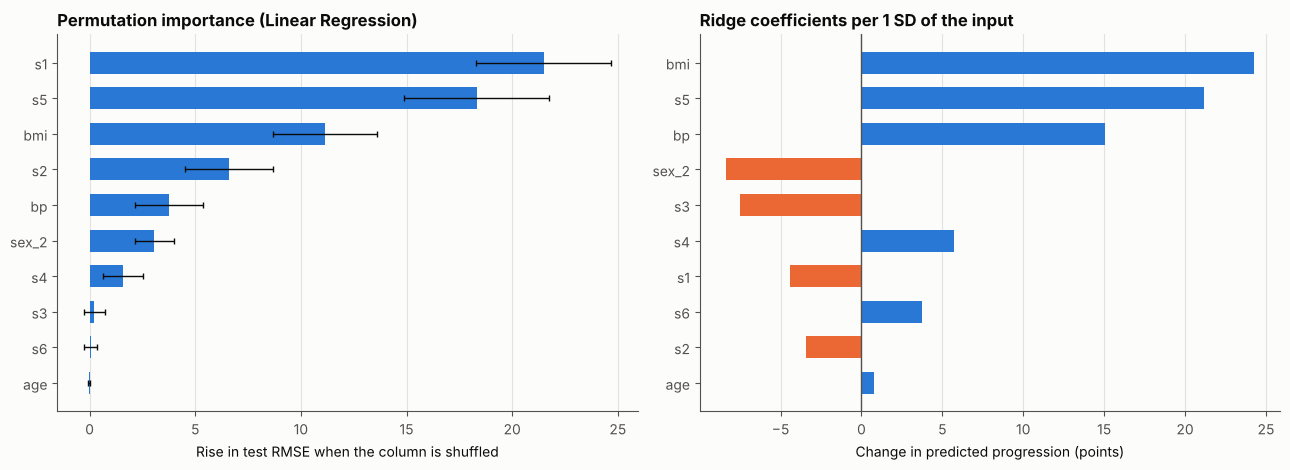

In [34]:
perm = permutation_importance(final_model, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=50, random_state=RANDOM_STATE)
imp = pd.DataFrame({"increase_in_RMSE": perm.importances_mean, "sd": perm.importances_std}, index=X_test.columns).sort_values("increase_in_RMSE", ascending=False)
R["perm_importance"] = imp.round(3).to_dict("index")
R["perm_top5"] = list(imp.index[:5])

# Standardised coefficients of the tuned Ridge model (inputs are z-scored, so they are comparable)
ridge_final = searches["Ridge"].best_estimator_
coef = pd.Series(ridge_final.named_steps["model"].coef_, index=ridge_final.named_steps["prep"].get_feature_names_out()).rename(lambda s: s.split("__")[-1])
coef = coef.sort_values(key=abs, ascending=False)
R["ridge_coef"] = coef.round(3).to_dict()
R["ridge_top5"] = list(coef.index[:5])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
imp_p = imp.iloc[::-1]
axes[0].barh(imp_p.index, imp_p["increase_in_RMSE"], xerr=imp_p["sd"], color=BLUE, height=0.62, error_kw={"ecolor": INK, "lw": 1, "capsize": 2})
axes[0].set(title=f"Permutation importance ({FINAL_NAME})", xlabel="Rise in test RMSE when the column is shuffled"); axes[0].grid(axis="y", visible=False)
cp = coef.iloc[:10].iloc[::-1]
axes[1].barh(cp.index, cp.values, color=[BLUE if v > 0 else ORANGE for v in cp.values], height=0.62)
axes[1].axvline(0, color=MUTED, lw=1)
axes[1].set(title="Ridge coefficients per 1 SD of the input", xlabel="Change in predicted progression (points)"); axes[1].grid(axis="y", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig14_feature_importance.png")
print("Permutation importance (rise in RMSE):"); print(imp.round(2).head(8).to_string())
print("\nRidge standardised coefficients:"); print(coef.round(1).head(10).to_string())

In [35]:
# Classical OLS on the standardised base predictors (training data): coefficient, t and p values.
Z = (train[BASE_NUM] - train[BASE_NUM].mean()) / train[BASE_NUM].std()
ols = pc.ols_summary(Z.values, y_train.values, BASE_NUM)
R["ols"] = ols.round(4).to_dict("index")
R["ols_sig"] = [i for i in ols.index[1:] if ols.loc[i, "p_value"] < 0.05]
ols.round(3)

,coef,std_err,t,p_value
intercept,151.929,2.916,52.099,0.000
age,0.405,3.184,0.127,0.899
sex_2,-9.366,3.315,-2.826,0.005
bmi,25.448,3.553,7.162,0.000
bp,15.632,3.587,4.358,0.000
s1,-32.774,22.006,-1.489,0.137
s2,18.164,17.948,1.012,0.312
s3,4.980,11.462,0.434,0.664
s4,8.852,8.747,1.012,0.312
s5,33.526,9.470,3.540,0.000


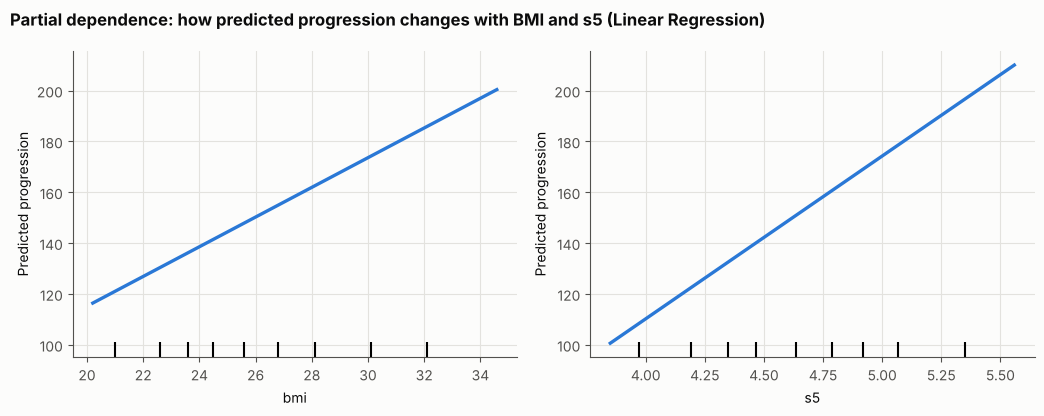

PosixPath('/home/claude/Final_Data_Science_Capstone/visualizations/generated_charts/fig15_partial_dependence.png')

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
PartialDependenceDisplay.from_estimator(final_model, X_train, ["bmi", "s5"], ax=axes, line_kw={"color": BLUE, "lw": 2.4}, grid_resolution=40)
for a in axes:
    a.set_ylabel("Predicted progression"); a.grid(True)
fig.suptitle(f"Partial dependence: how predicted progression changes with BMI and s5 ({FINAL_NAME})", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
pc.save_figure(fig, "fig15_partial_dependence.png")

**What the charts show.** Left: how much the test error rises when one column is randomly shuffled (permutation importance). Right: Ridge coefficients per one standard deviation of each input. The table above gives the classical regression (OLS) coefficients with significance tests. The partial-dependence plots show how the predicted progression changes with BMI and `s5` when everything else is averaged out.

**Observation.**

* **Robust drivers.** `bmi`, `s5` and `bp` stand out in every view: they top the Ridge coefficients (+24.2, +21.2 and +15.0 points per SD), and each is significant in the regression (t = 7.2, 3.5 and 4.4). Predicted progression rises almost in a straight line with BMI and `s5`.
* **Sex.** After adjusting for the other measurements, sex code 2 has a significantly lower predicted progression (-9.4 points, p = 0.005), although the raw averages hardly differed (section 10.3). The direction cannot be interpreted because the code meaning is not documented.
* **Cholesterol group (`s1`-`s4`).** Permutation importance ranks `s1` first (21.5) and `s2` fourth, but in the regression `s1` and `s2` have opposite signs and are individually non-significant (p = 0.14 and 0.31). This is the multicollinearity warned about earlier: the model uses the *contrast* between the two correlated measurements, so their individual importance must **not** be over-interpreted. HDL (`s3`) is protective in simple comparisons (-0.37) but adds little once the other measurements are included (p = 0.66).

**Top five factors, in plain language.** (1) Body mass index; (2) serum triglycerides (`s5`); (3) blood pressure; (4) the group of cholesterol measurements (`s1`-`s4`, taken together, with HDL on the protective side); (5) sex (after adjustment). The first three are the most dependable.

**Important distinction.** *Correlation* shows that two things move together; *feature importance* shows what the **model** relies on; neither proves **causation**. These results describe associations in this dataset only.

### 15.2 High-risk patient segments (training set, thresholds fixed from training quartiles)

Thresholds (from training data): {'bmi': np.float64(29.2), 's5': np.float64(4.997), 'bp': np.float64(104.0), 's3': np.float64(41.0)}
 risk_indicators   n  mean  share_high_%      set
               0 153 108.2           5.9 Training
               1  83 148.1          16.9 Training
               2  73 201.9          47.9 Training
               3  36 222.8          63.9 Training
               4   8 253.6         100.0 Training
               0  35 107.3           2.9     Test
               1  25 141.8          24.0     Test
               2  15 196.5          40.0     Test
               3   8 225.9          75.0     Test
               4   6 259.7         100.0     Test
Spearman(indicators, progression): training +0.58; test +0.60 (p = 5.1e-10)

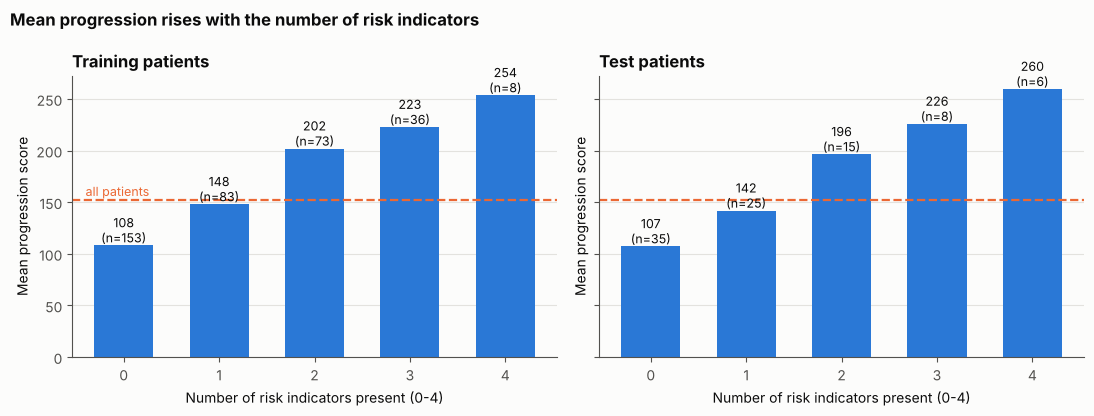

In [37]:
thr = {"bmi": train["bmi"].quantile(0.75), "s5": train["s5"].quantile(0.75), "bp": train["bp"].quantile(0.75), "s3": train["s3"].quantile(0.25)}
R["thresholds"] = {k: float(v) for k, v in thr.items()}


def indicator_count(d):
    """Number of risk indicators present: high BMI, high s5, high blood pressure, low HDL (s3)."""
    return ((d["bmi"] >= thr["bmi"]).astype(int) + (d["s5"] >= thr["s5"]).astype(int) +
            (d["bp"] >= thr["bp"]).astype(int) + (d["s3"] <= thr["s3"]).astype(int))


train["risk_indicators"], test["risk_indicators"] = indicator_count(train), indicator_count(test)
high_cut = float(train[TARGET].quantile(0.75))               # "high progression" = top 25% of the training patients
R["high_cut"] = high_cut
rows = []
for label, d in (("Training", train), ("Test", test)):
    g = d.groupby("risk_indicators")[TARGET].agg(n="size", mean="mean")
    g["share_high_%"] = d.groupby("risk_indicators")[TARGET].apply(lambda s: 100 * (s >= high_cut).mean())
    g["set"] = label
    rows.append(g.reset_index())
seg = pd.concat(rows)
R["segments"] = {lab: g.drop(columns="set").round(1).to_dict("records") for lab, g in seg.groupby("set")}
for tag, d in (("tr", train), ("te", test)):
    for k in range(5):
        sub = d.loc[d["risk_indicators"] == k, TARGET]
        R[f"ind_{tag}_n_{k}"], R[f"ind_{tag}_mean_{k}"], R[f"ind_{tag}_high_{k}"] = len(sub), sub.mean(), 100 * (sub >= high_cut).mean()
rho_tr, p_tr = stats.spearmanr(train["risk_indicators"], train[TARGET]); rho_te, p_te = stats.spearmanr(test["risk_indicators"], test[TARGET])
R["indicator_rho"], R["indicator_rho_test"], R["indicator_p_test"] = rho_tr, rho_te, p_te
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (label, g) in zip(axes, seg.groupby("set", sort=False)):
    ax.bar(g["risk_indicators"], g["mean"], color=BLUE, width=0.62)
    ax.axhline(df_all[TARGET].mean(), color=ORANGE, lw=1.6, ls="--")
    for xi, m, n in zip(g["risk_indicators"], g["mean"], g["n"]):
        ax.text(xi, m + 3, f"{m:.0f}\n(n={n})", ha="center", fontsize=9)
    ax.set(title=f"{label} patients", xlabel="Number of risk indicators present (0-4)", ylabel="Mean progression score"); ax.grid(axis="x", visible=False)
axes[0].text(-0.4, df_all[TARGET].mean() + 4, "all patients", color=ORANGE, fontsize=9)
fig.suptitle("Mean progression rises with the number of risk indicators", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
pc.save_figure(fig, "fig16_risk_indicator_segments.png")
print("Thresholds (from training data):", {k: round(v, 3) for k, v in thr.items()})
print(seg.round(1).to_string(index=False))
print(f"Spearman(indicators, progression): training {rho_tr:+.2f}; test {rho_te:+.2f} (p = {p_te:.1e})")

In [38]:
# Other single-variable segments (training set): mean progression and the share of patients in the top 25%
def seg_table(d, col, bins, labels):
    c = pd.cut(d[col], bins, labels=labels, include_lowest=True)
    g = d.groupby(c, observed=True)[TARGET].agg(n="size", mean="mean")
    g["share_high_%"] = d.groupby(c, observed=True)[TARGET].apply(lambda s: 100 * (s >= high_cut).mean())
    return g


s5_q = train["s5"].quantile([0, .25, .5, .75, 1]).values
bp_q = train["bp"].quantile([0, .25, .5, .75, 1]).values
s3_q = train["s3"].quantile([0, .25, .5, .75, 1]).values
seg_s5 = seg_table(train, "s5", s5_q, ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
seg_bp = seg_table(train, "bp", bp_q, ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
seg_s3 = seg_table(train, "s3", s3_q, ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
R["seg_s5"], R["seg_bp"], R["seg_s3"] = (x.round(1).to_dict("index") for x in (seg_s5, seg_bp, seg_s3))
bmi_hi = train.groupby("bmi_category", observed=True)[TARGET].agg(n="size", mean="mean")
bmi_hi["share_high_%"] = train.groupby("bmi_category", observed=True)[TARGET].apply(lambda s: 100 * (s >= high_cut).mean())
R["seg_bmi"] = bmi_hi.round(1).to_dict("index")
for title, t in (("BMI class", bmi_hi), ("s5 quartile", seg_s5), ("Blood-pressure quartile", seg_bp), ("s3 (HDL) quartile", seg_s3)):
    print(f"\n{title}"); print(t.round(1).to_string())

BMI class
                n   mean  share_high_%
bmi_category                          
Under 25      154  110.9           6.5
25 to 29.9    123  165.1          30.1
30 and over    76  213.8          55.3

s5 quartile
               n   mean  share_high_%
s5                                   
Q1 (lowest)   90   94.1           0.0
Q2            89  131.6          14.6
Q3            86  174.3          29.1
Q4 (highest)  88  209.8          58.0

Blood-pressure quartile
               n   mean  share_high_%
bp                                   
Q1 (lowest)   93  119.6           8.6
Q2            87  132.3          14.9
Q3            85  154.9          25.9
Q4 (highest)  88  202.7          52.3

s3 (HDL) quartile
               n   mean  share_high_%
s3                                   
Q1 (lowest)   99  184.7          40.4
Q2            84  165.0          31.0
Q3            83  144.9          20.5
Q4 (highest)  87  108.7           6.9

**Method.** Four easy-to-check risk indicators were defined from training-set thresholds (so nothing is learned from the test patients): BMI at or above 29.2, `s5` at or above 5.00, blood pressure at or above 104 (the top quarter in each case) and HDL (`s3`) at or below 41 (the bottom quarter). "High progression" means a score of 208 or more (the top 25 % of training patients).

**Observation.**

| Risk indicators present | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| Training: mean progression | 108 | 148 | 202 | 223 | 254 |
| Training: patients | 153 | 83 | 73 | 36 | 8 |
| Training: share with high progression | 6 % | 17 % | 48 % | 64 % | 100 % |
| **Test**: mean progression | 107 | 142 | 196 | 226 | 260 |
| **Test**: patients | 35 | 25 | 15 | 8 | 6 |

Mean progression climbs steadily from about 108 (no indicator) to about 254 (all four), and the **same pattern appears in the unseen test patients** (rank correlation +0.60, p = 5e-10). A patient with two or more indicators is far more likely to be in the high group (48 % at two indicators in training) than one with none (6 %). Single variables show the same direction: 55 % of patients with BMI 30 and over are high progressors versus 6 % under 25; for `s5`, 58 % in the top quarter versus 0 % in the bottom quarter; for blood pressure 52 % versus 9 %; and for HDL 40 % in the lowest quarter versus 7 % in the highest.

**Limitation.** The groups with three or four indicators are small (the four-indicator group has only 8 training and 6 test patients), so their exact values are uncertain; the overall upward trend is the reliable finding. These are associations, not proof that changing a value changes progression.

### 15.3 Extension: flagging patients likely to progress quickly

High-progression label: progression >= 208.0 (top 25% of the training data); 25 of 89 test patients
{'Linear Regression (predicted progression)': 0.921, 'BMI alone': 0.842, 'Risk-indicator count': 0.866}

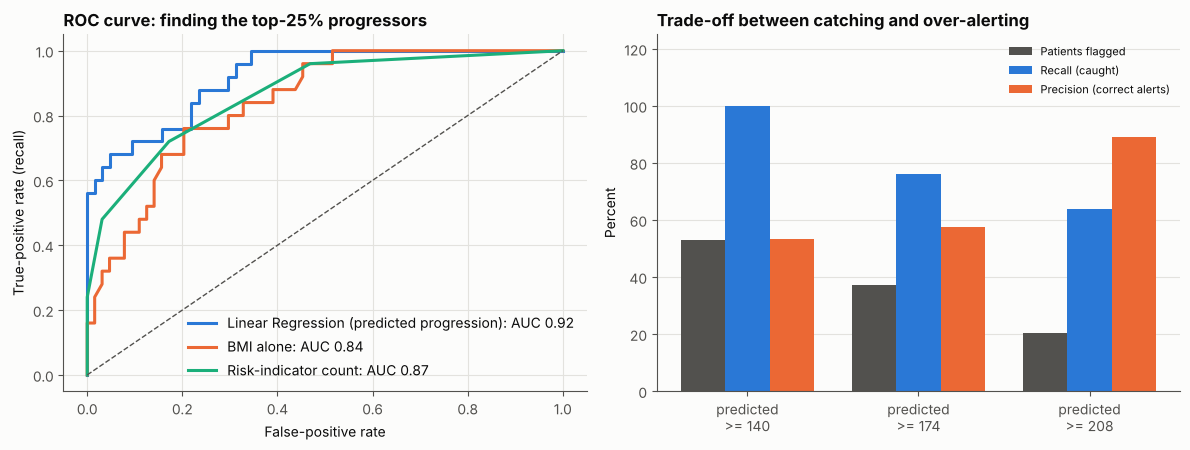

,alert_if_predicted_>=,flagged_%,recall_%,precision_%,TP,FP,FN,TN
0,140.0,52.8,100.0,53.2,25,22,0,42
1,174.0,37.1,76.0,57.6,19,14,6,50
2,208.0,20.2,64.0,88.9,16,2,9,62


In [39]:
y_high_test = (y_test >= high_cut).astype(int)
R["n_high_test"] = int(y_high_test.sum())
scores = {FINAL_NAME + " (predicted progression)": pred_test, "BMI alone": test["bmi"].values,
          "Risk-indicator count": test["risk_indicators"].values}
auc = {k: roc_auc_score(y_high_test, v) for k, v in scores.items()}
R["auc"] = auc
R["auc_model"], R["auc_bmi"], R["auc_ind"] = list(auc.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for (k, v), c in zip(scores.items(), [BLUE, ORANGE, AQUA]):
    fpr, tpr, _ = roc_curve(y_high_test, v)
    axes[0].plot(fpr, tpr, color=c, lw=2.2, label=f"{k}: AUC {auc[k]:.2f}")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[0].set(title="ROC curve: finding the top-25% progressors", xlabel="False-positive rate", ylabel="True-positive rate (recall)"); axes[0].legend(loc="lower right")
cuts = np.percentile(y_train, [50, 62.5, 75])
rows = []
for c in cuts:
    flagged = pred_test >= c
    tn, fp, fn, tp = confusion_matrix(y_high_test, flagged).ravel()
    rows.append({"alert_if_predicted_>=": c, "flagged_%": 100 * flagged.mean(), "recall_%": 100 * tp / (tp + fn),
                 "precision_%": 100 * tp / max(tp + fp, 1), "TP": tp, "FP": fp, "FN": fn, "TN": tn})
alert = pd.DataFrame(rows).round(1)
R["alert_table"] = alert.to_dict("records")
for i, row in alert.iterrows():
    R[f"alert_cut_{i}"], R[f"alert_flag_{i}"], R[f"alert_recall_{i}"], R[f"alert_prec_{i}"] = row["alert_if_predicted_>="], row["flagged_%"], row["recall_%"], row["precision_%"]
    R[f"alert_tp_{i}"], R[f"alert_fp_{i}"], R[f"alert_fn_{i}"] = int(row["TP"]), int(row["FP"]), int(row["FN"])
xb = np.arange(len(alert)); w = 0.26
axes[1].bar(xb - w, alert["flagged_%"], w, color=MUTED, label="Patients flagged")
axes[1].bar(xb, alert["recall_%"], w, color=BLUE, label="Recall (caught)")
axes[1].bar(xb + w, alert["precision_%"], w, color=ORANGE, label="Precision (correct alerts)")
axes[1].set_xticks(xb, [f"predicted\n>= {c:.0f}" for c in alert["alert_if_predicted_>="]]); axes[1].set(title="Trade-off between catching and over-alerting", ylabel="Percent")
axes[1].legend(loc="upper right", fontsize=8, ncol=1); axes[1].set_ylim(0, 125); axes[1].grid(axis="x", visible=False)
plt.tight_layout()
pc.save_figure(fig, "fig17_high_risk_extension.png")
print(f"High-progression label: progression >= {high_cut:.1f} (top 25% of the training data); {R['n_high_test']} of {len(y_test)} test patients");
print({k: round(v, 3) for k, v in auc.items()}); alert

**Question.** Instead of the exact score, can the model tell which patients will be *fast progressors* (top 25 %)? Here, classification metrics apply.

**Observation.** In the 89 test patients, 25 are fast progressors. Using the model's predicted score as the ranking, **ROC-AUC = 0.92** (1.0 is perfect, 0.5 is guessing). This is better than ranking by BMI alone (0.84) or by the risk-indicator count (0.87). The right-hand chart shows what happens when an alert is raised at three cut-offs of the predicted score:

| Alert if predicted score is at least | Patients flagged | Fast progressors caught (recall) | Alerts that were correct (precision) | Missed (false negatives) |
|---|---|---|---|---|
| 140 | 53 % | 100 % | 53 % | 0 |
| 174 | 37 % | 76 % | 58 % | 6 |
| 208 | 20 % | 64 % | 89 % | 9 |

**Interpretation.** A **false negative** (a fast progressor who is not flagged) means a patient who needed attention was missed; a **false positive** means an unnecessary alert. For a screening tool, missing a high-risk patient is usually worse than an extra check, so **recall** is the key metric and a lower cut-off is preferable: the lowest cut-off catches every fast progressor in this test set but flags about half of all patients. A higher cut-off is more precise but misses more. The right cut-off depends on how many patients a clinic can follow up.

**Limitation.** Only 25 fast progressors are in the test set, so these percentages could shift noticeably with different patients. They indicate the trade-off; they are not guaranteed performance.

## 16. Recommendations

Each recommendation is tied to a finding. They are **analytical proposals** for a (hypothetical) clinic; clinical staff must review them, and the expected effect is a direction, not a promised outcome.

| ID | Supporting finding | Proposed action | Priority | KPI to measure success | How to test it |
|---|---|---|---|---|---|
| R1 | Predicted score separates fast progressors well (AUC 0.92); 4 indicators give a steady rise in progression | Use the model score (or the 4-indicator count when no software is available) as a **triage ranking** for follow-up appointments | High | Share of fast progressors reviewed early; recall of flagged patients | Run the ranking in parallel with normal scheduling for a few months and compare |
| R2 | 55 % of patients with BMI 30 and over are fast progressors vs 6 % under 25 | Offer **weight-management support first** to the BMI 30+ group | High | Change in BMI and in progression score after 12 months | Pilot with a comparison group (needed because this is only an association) |
| R3 | Triglyceride marker `s5` and blood pressure are robust drivers; progression rises with each extra indicator | **Review lipid and blood-pressure results together** and flag patients with two or more indicators | Medium | Share of 2+ indicator patients with a documented plan | Audit records quarterly |
| R4 | Recall rises and precision falls as the alert cut-off is lowered (section 15.3) | **Choose the cut-off from capacity:** a low cut-off for screening, a high cut-off for scarce interventions | Medium | Recall and precision on live data | Track false negatives and false positives monthly |
| R5 | Predictions are about 42 points off on average and the extremes are systematically compressed | Show predictions as a **ranking or range, not an exact score**; treat the highest-risk patients as likely to be *worse* than predicted | Medium | Calibration of predicted vs actual in new patients | Re-check residuals by risk band every six months |
| R6 | About half the variation is unexplained and the learning curve is flat | **Collect richer data** (repeat measurements, lifestyle, medication, a defined score) before building a more complex model | Medium | Improvement in cross-validated RMSE after adding variables | Add variables to a small pilot and re-run this notebook |

**Risks and assumptions.** Association is not causation; the data come from one source and an unknown population; the model must be validated on local patients before any use.

## 17. Limitations

1. **Small, single-source data:** 442 patients, with no information on selection, place or time. Results may not apply elsewhere.
2. **No external validation:** performance was measured on a held-out part of the same dataset; the 95 % interval for test R-squared (0.39 to 0.67) shows how uncertain even that is.
3. **Moderate predictive power:** only about half of the variation is explained and individual predictions can be 100 points off.
4. **Multicollinearity:** the cholesterol measurements overlap, so individual coefficients for `s1`-`s4` are unreliable.
5. **Unclear variables:** the target has no unit, the sex codes are undocumented and `s4` differs slightly from `s1 / s3`.
6. **Association, not causation:** all findings describe relationships in observational data.
7. **Small subgroups:** group-level error and segment results rest on few patients, especially the three- and four-indicator groups.
8. **Not a clinical tool:** no medical, ethical or fairness review was carried out.

## 18. Conclusion

The project answered its seven questions with a complete, reproducible workflow. The data were complete and unique; BMI, serum triglycerides (`s5`) and blood pressure are the most reliable indicators of faster progression; engineered features did not improve prediction; and the simplest tuned model, **Linear Regression**, was selected because five models were statistically tied. On 89 unseen patients it reached an RMSE of 52.0 points and an R-squared of 0.55, a **33 % reduction in error** compared with predicting the average, without overfitting. The model is best used to *rank* patients: it identifies likely fast progressors well (AUC 0.92) but compresses extreme scores and leaves much variation unexplained. The most valuable next step is better data, not a more complex algorithm.

## 19. Future scope

* **Validate externally** on a different patient group or a later time period.
* **Collect richer data:** repeated measurements, lifestyle, medication, treatment history and a precisely defined outcome.
* **Try further methods** (interactions, splines, quantile regression for prediction intervals, XGBoost and SHAP explanations once the packages are available).
* **Check fairness and subgroup performance** by age and sex once the sex coding is documented.
* **Turn the model into a simple tool** (for example a dashboard with the risk indicators and an alert threshold) and monitor it with the review plan in R5.
* **Add calibration and decision-curve analysis** to choose alert thresholds with clinicians.

## 20. Saving the results and verifying the numbers

In [40]:
# 1) trained model, 2) processed data, 3) evaluation table, 4) key results (read by the report and slides)
(PROJECT_ROOT / "models").mkdir(exist_ok=True); (PROJECT_ROOT / "results").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "name": FINAL_NAME, "features": NUM_COLS + CAT_COLS, "numeric": NUM_COLS, "categorical": CAT_COLS,
             "random_state": RANDOM_STATE, "scikit_learn_version": __import__("sklearn").__version__}, PROJECT_ROOT / "models" / "best_model.joblib")
processed = pd.concat([train.assign(split="train"), test.assign(split="test")]).sort_index()
processed.to_csv(pc.PROCESSED_CSV, index=True, index_label="patient_id")
out = results.round(4).copy(); out.insert(0, "selected", out.index == FINAL_NAME)
out.to_csv(PROJECT_ROOT / "results" / "model_evaluation_results.csv", index_label="model")
pd.DataFrame({"actual": y_test, "predicted": pred_test, "residual": resid}).round(3).to_csv(PROJECT_ROOT / "results" / "test_predictions.csv", index_label="patient_id")


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o


with open(PROJECT_ROOT / "results" / "key_results.json", "w") as f:
    json.dump(jsonable(R), f, indent=1)
print("Saved: models/best_model.joblib, data/processed/..., results/model_evaluation_results.csv, results/test_predictions.csv, results/key_results.json")

Saved: models/best_model.joblib, data/processed/..., results/model_evaluation_results.csv, results/test_predictions.csv, results/key_results.json

In [41]:
# Independent re-calculation of the headline numbers (does not reuse src/ functions)
saved = pd.read_csv(PROJECT_ROOT / "results" / "test_predictions.csv")
e = saved["actual"] - saved["predicted"]
rmse_chk, mae_chk = float(np.sqrt((e ** 2).mean())), float(e.abs().mean())
r2_chk = 1 - float((e ** 2).sum() / ((saved["actual"] - saved["actual"].mean()) ** 2).sum())
reloaded = joblib.load(PROJECT_ROOT / "models" / "best_model.joblib")["model"]
checks = {
    "test RMSE recomputed": abs(rmse_chk - R["test"]["RMSE"]) < 1e-2,
    "test MAE recomputed": abs(mae_chk - R["test"]["MAE"]) < 1e-2,
    "test R2 recomputed": abs(r2_chk - R["test"]["R2"]) < 1e-3,
    "reloaded model reproduces predictions": bool(np.allclose(reloaded.predict(X_test), pred_test)),
    "train + test = all patients": R["n_train"] + R["n_test"] == R["n_rows"],
    "no patient in both sets": len(set(train.index) & set(test.index)) == 0,
    "selected model chosen from CV, not test": FINAL_NAME in R["eligible_models"],
    "17 charts saved": len(list((PROJECT_ROOT / "visualizations" / "generated_charts").glob("fig*.png"))) == 17,
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "a verification check failed"
print(f"\nAll {len(checks)} checks passed.")

PASS  test RMSE recomputed
PASS  test MAE recomputed
PASS  test R2 recomputed
PASS  reloaded model reproduces predictions
PASS  train + test = all patients
PASS  no patient in both sets
PASS  selected model chosen from CV, not test
PASS  17 charts saved

All 8 checks passed.

In [42]:
# The written interpretation makes qualitative claims. Each one is checked against the computed results.
cp, five = R["corr_pearson"], ["Linear Regression", "Ridge", "Lasso", "Random Forest", "Gradient Boosting"]
cv5 = [R["results_table"][m]["cv_rmse"] for m in five]
claims = {
    "BMI has the strongest correlation with progression": max(cp, key=lambda k: abs(cp[k])) == "bmi",
    "sex is the only predictor not significant after Bonferroni": [k for k, v in R["corr_sig"].items() if not v] == ["sex"],
    "engineered features did not help (decision = not adopted)": R["use_engineered"] is False,
    "five models are within two standard errors of each other": max(cv5) - min(cv5) < 2 * R["results_table"]["Ridge"]["cv_rmse_se"],
    "decision tree is clearly the weakest tuned model": R["results_table"]["Decision Tree"]["cv_rmse"] > max(cv5) + R["results_table"]["Ridge"]["cv_rmse_se"],
    "final model beats the baseline by more than 25% (success criterion)": R["rmse_gain_vs_baseline_pct"] > 25 and 100 * (1 - R["cv"]["RMSE"] / R["baseline_cv_rmse"]) > 25,
    "no overfitting: train-to-CV RMSE gap below 3": R["train_cv_gap"][FINAL_NAME] < 3,
    "ensembles overfit more than the linear model": min(R["train_cv_gap"][m] for m in ["Random Forest", "Gradient Boosting", "Decision Tree"]) > 5,
    "model slightly over-predicts the lowest band and under-predicts the highest": R["err_by_band"]["Lowest 25%"]["mean_residual"] < 0 < R["err_by_band"]["Highest 25%"]["mean_residual"],
    "errors are largest at the extremes": min(R["err_by_band"]["Lowest 25%"]["MAE"], R["err_by_band"]["Highest 25%"]["MAE"]) > max(R["err_by_band"]["25-50%"]["MAE"], R["err_by_band"]["50-75%"]["MAE"]),
    "OLS-significant predictors are sex, bmi, bp and s5": set(R["ols_sig"]) == {"sex_2", "bmi", "bp", "s5"},
    "ridge top-3 are bmi, s5, bp": R["ridge_top5"][:3] == ["bmi", "s5", "bp"],
    "risk indicators rise monotonically (training and test)": all(R[f"ind_{t}_mean_{k}"] < R[f"ind_{t}_mean_{k+1}"] for t in ("tr", "te") for k in range(4)),
    "AUC: model > indicator count > BMI alone": R["auc_model"] > R["auc_ind"] > R["auc_bmi"],
    "lower alert cut-off gives higher recall and lower precision": R["alert_recall_0"] >= R["alert_recall_1"] >= R["alert_recall_2"] and R["alert_prec_0"] <= R["alert_prec_2"],
    "outlier patients do not drive the result (test RMSE within 3 points)": abs(R["sens_rmse"] - R["test"]["RMSE"]) < 3,
}
for k, v in claims.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(claims.values()), "a claim made in the narrative is not supported by the results"
print(f"\nAll {len(claims)} narrative claims are supported by the computed results.")

PASS  BMI has the strongest correlation with progression
PASS  sex is the only predictor not significant after Bonferroni
PASS  engineered features did not help (decision = not adopted)
PASS  five models are within two standard errors of each other
PASS  decision tree is clearly the weakest tuned model
PASS  final model beats the baseline by more than 25% (success criterion)
PASS  no overfitting: train-to-CV RMSE gap below 3
PASS  ensembles overfit more than the linear model
PASS  model slightly over-predicts the lowest band and under-predicts the highest
PASS  errors are largest at the extremes
PASS  OLS-significant predictors are sex, bmi, bp and s5
PASS  ridge top-3 are bmi, s5, bp
PASS  risk indicators rise monotonically (training and test)
PASS  AUC: model > indicator count > BMI alone
PASS  lower alert cut-off gives higher recall and lower precision
PASS  outlier patients do not drive the result (test RMSE within 3 points)

All 16 narrative claims are supported by the computed re

**All checks passed.** The code cells above re-computed the headline metrics independently of `src/`, confirmed that the saved model reproduces its predictions, that the training and test patients do not overlap, and that every qualitative statement in this notebook is supported by the computed results. Numbers in the text are not typed by hand: they are filled from the executed code (the dictionary `R`), which is also saved to `results/key_results.json` and used to build the report and slides.

**Objective-to-evidence map**

| Official objective | Where it is demonstrated |
|---|---|
| 1. Define the capstone problem | Sections 1-3 |
| 2. Collect and prepare data | Sections 4-11 |
| 3. Apply data-science techniques | Sections 12 and 15 |
| 4. Build and evaluate the solution | Sections 12-13 |
| 5. Analyse results, errors, limitations | Sections 13.1, 14, 17, 19 |
| 6. Generate insights and recommendations | Sections 15-16 |
| 7. Document and present | This notebook, `reports/Final Data Science Capstone Project.docx`, `presentation/Final_Project_Presentation.pptx`, `README.md` |